## Финальный проект

#### *«Я чувствую себя как функция арктангенса, которая приближается к асимптоте.» — Теория большого взрыва*

Это финальный проект продуктового блока курса «Продуктовые метрики». За него можно получить максимум 60 баллов. 

**Дедлайны**   
Жесткий дедлайн: 25.10.2026 23:59 по МСК. 

После жесткого дедлайна работы не принимаются. 

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание аннулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например final_project). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/final_project_data.zip)

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import requests

from statsmodels.tsa.seasonal import STL
from scipy.stats import norm
from scipy.stats import t
import math

import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')

### Case Study. Улучшение сервиса доставки из ресторанов 🌮

**Легенда**   
Вы присоединились к продуктовой команде сервиса доставки из ресторанов в роли аналитика. Близится планирование следующего квартала, пора готовить бэклог инициатив. Продакт-менеджер особенно беспокоится об удовлетворенности пользователей — за последний месяц выросло число отмен и жалоб на задержки.

Вам поставлена задача: провести исследование текущих значений метрик, выдвинуть гипотезу о проблеме и предложить её решение.

In [3]:
df = pd.read_csv('final_project_delivery.csv')

df.head()

,order_id,order_time,delivery_time,status,cancellation_reason,order_value,delivery_fee,estimated_delivery_time_min,time_to_assign_courier_min,actual_preparation_time_min,travel_time_min,delivery_distance_km,promotion_used,platform,city_region,user_id,user_segment
0,257,2022-11-01 00:01:46,2022-11-01 00:21:52,delivered,NaN,25.73,2.09,27.0,10.2,15.1,5.0,3.48,no,Android,Belem,5737,returning
1,165,2022-11-01 00:06:07,2022-11-01 00:27:01,delivered,NaN,22.00,0.77,13.0,9.0,15.9,5.0,1.29,no,iOS,Parque das Nacoes,4095,new
2,343,2022-11-01 21:07:01,2022-11-01 21:40:07,delivered,NaN,29.90,3.53,44.0,10.6,15.4,15.1,5.88,no,iOS,Parque das Nacoes,15991,returning
3,904,2022-11-01 00:06:48,2022-11-01 00:36:42,delivered,NaN,40.49,2.02,27.0,3.7,16.0,13.9,3.36,no,Android,Alfama,1773,returning
4,555,2022-11-01 00:09:58,2022-11-01 00:57:22,delivered,NaN,35.75,3.48,39.0,5.2,12.3,35.1,5.80,no,iOS,Baixa,5203,returning


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74992 entries, 0 to 74991
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   order_id                     74992 non-null  int64  
 1   order_time                   74992 non-null  object 
 2   delivery_time                69421 non-null  object 
 3   status                       74992 non-null  object 
 4   cancellation_reason          5571 non-null   object 
 5   order_value                  74992 non-null  float64
 6   delivery_fee                 74992 non-null  float64
 7   estimated_delivery_time_min  74992 non-null  float64
 8   time_to_assign_courier_min   69421 non-null  float64
 9   actual_preparation_time_min  69682 non-null  float64
 10  travel_time_min              69421 non-null  float64
 11  delivery_distance_km         74992 non-null  float64
 12  promotion_used               74992 non-null  object 
 13  platform        

Описание данных:

- order_id — уникальный идентификатор заказа
- order_time — timestamp создания заказа
- delivery_time – timestamp доставки заказа
- status — статус заказа, принимает 2 значения: delivered и cancelled
- cancellation_reason — причина отмены заказа: Cancelled by user (отменена пользователем) и No courier available (нет доступных курьеров)
- order_value — стоимость заказа
- delivery_fee — стоимость доставки
- estimated_delivery_time_min — прогнозное время доставки
- time_to_assign_courier_min — время до назначения курьера
- actual_preparation_time_min — время приготовления заказа рестораном
- travel_time_min — суммарное время на дорогу курьера до ресторана и до конечного пользователя
- delivery_distance_km — расстояние от адреса доставки до адреса ресторана
- promotion_used — был ли заказ совершен с использованием промокода или акции
- platform — платформа, с которой совершен заказ
- city_region — район города, в который планируется доставка
- user_id — уникальный идентификатор пользователя, сделавшего заказ
- user_segment — сегмент пользователя (новый или вернувшийся)    

### Часть 1. Исследование

#### 1. Динамика основных метрик — 3 балла
Рассчитайте и визуализируйте по дням:
- Число заказов, число доставленных заказов (статус delivered);
- Completion Rate (Доставленные заказы/Все заказы), Cancellation Rate (Отмененные заказы/Все заказы);
- Среднее и медианное время доставки в минутах (рассчитывается как разница между delivery_time и order_time), средний чек заказа, среднюю стоимость доставки.

Сделайте выводы:
- Есть ли выраженный тренд?
- Может быть какие-то дни кажутся подозрительными на предмет аномалий?

In [5]:
# your code is here
# преобразование времени
df['order_time'] = pd.to_datetime(df['order_time'])
df['delivery_time'] = pd.to_datetime(df['delivery_time'])
df['order_date'] = df['order_time'].dt.date
df['delivery_duration_min'] = (df['delivery_time'] - df['order_time']).dt.total_seconds()/60

In [6]:
# агрегирую по дням
daily_metrics = df.groupby('order_date').agg(
    total_orders=('order_id', 'count'),
    delivered_orders=('status', lambda x: (x == 'delivered').sum()),
    cancelled_orders=('status', lambda x: (x == 'cancelled').sum()),
    avg_delivery_time=('delivery_duration_min', 'mean'),
    median_delivery_time=('delivery_duration_min', 'median'),
    avg_order_value=('order_value', 'mean'),
    avg_delivery_fee=('delivery_fee', 'mean')
).reset_index()

In [7]:
daily_metrics['completion_rate'] = daily_metrics['delivered_orders']/daily_metrics['total_orders']
daily_metrics['cancellation_rate'] = daily_metrics['cancelled_orders']/daily_metrics['total_orders']

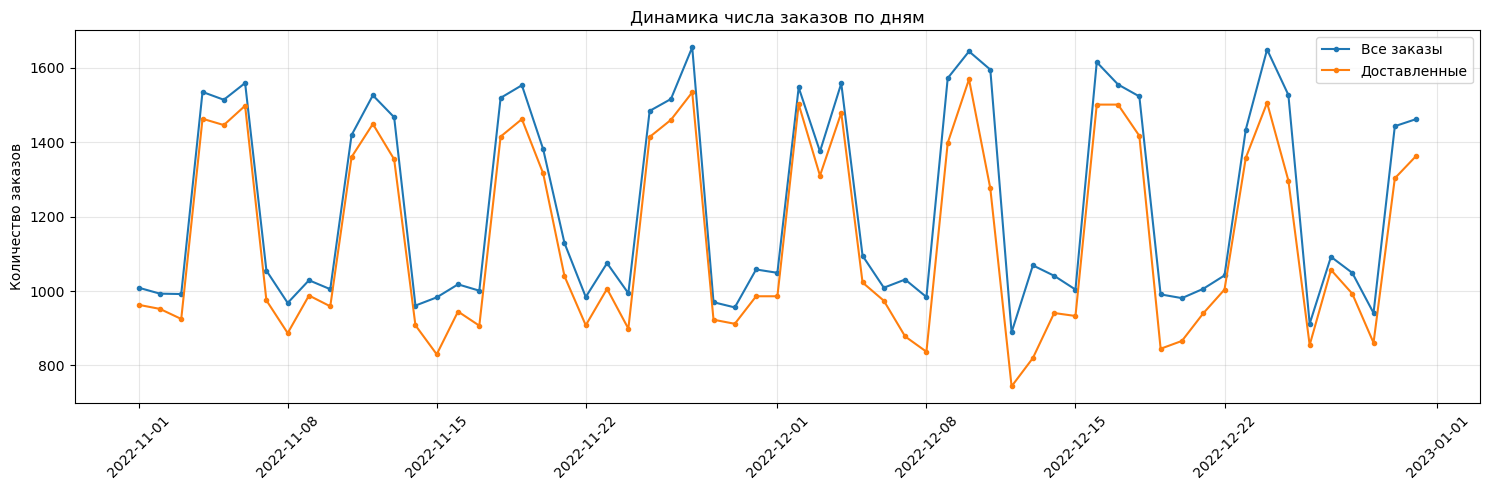

In [8]:
# Число заказов и доставленных заказов
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily_metrics['order_date'], daily_metrics['total_orders'], label='Все заказы', marker='.')
ax.plot(daily_metrics['order_date'], daily_metrics['delivered_orders'], label='Доставленные', marker='.')
ax.set_title('Динамика числа заказов по дням')
ax.set_ylabel('Количество заказов')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

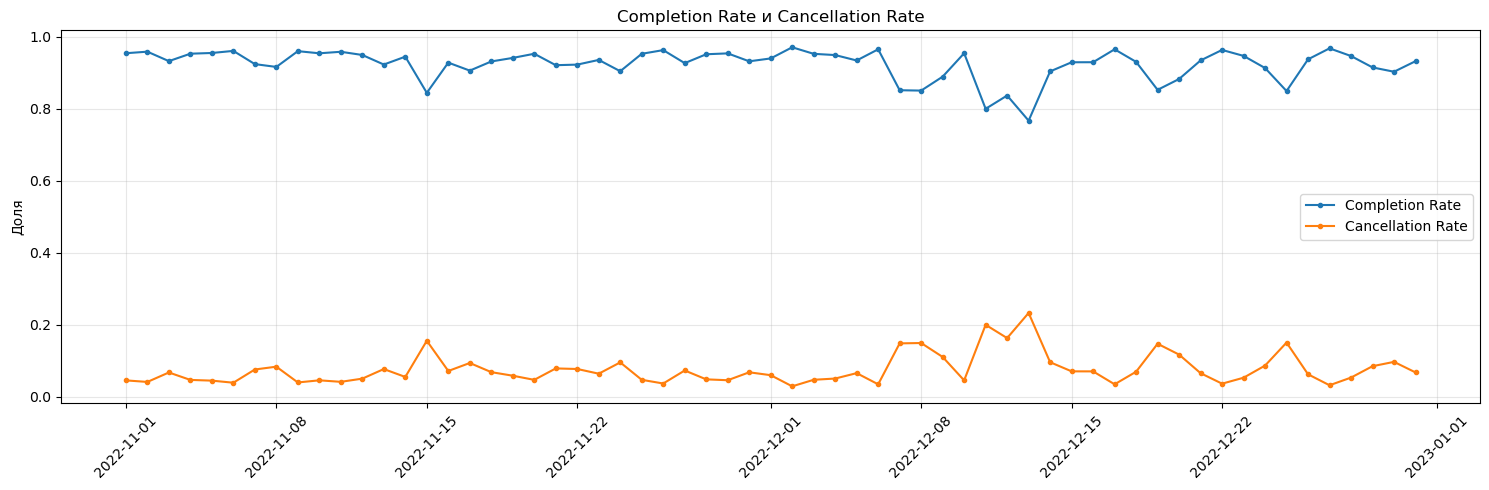

In [9]:
# Completion Rate и Cancellation Rate
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily_metrics['order_date'], daily_metrics['completion_rate'], label='Completion Rate', marker='.')
ax.plot(daily_metrics['order_date'], daily_metrics['cancellation_rate'], label='Cancellation Rate', marker='.')
ax.set_title('Completion Rate и Cancellation Rate')
ax.set_ylabel('Доля')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

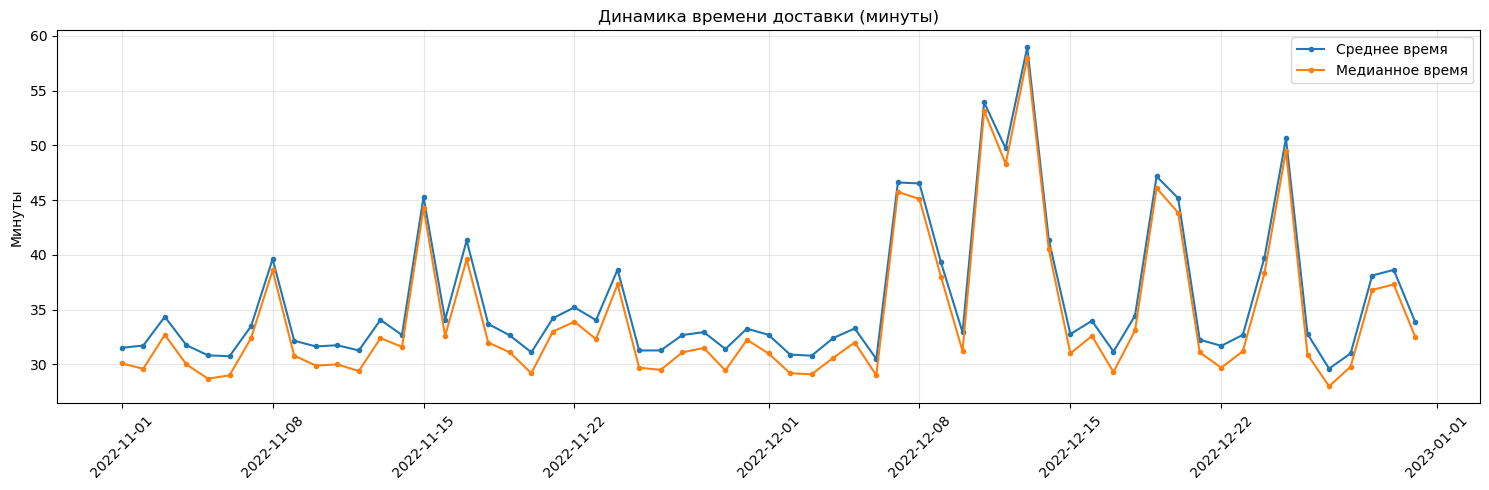

In [10]:
# Среднее и медианное время доставки
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily_metrics['order_date'], daily_metrics['avg_delivery_time'], label='Среднее время', marker='.')
ax.plot(daily_metrics['order_date'], daily_metrics['median_delivery_time'], label='Медианное время', marker='.')
ax.set_title('Динамика времени доставки (минуты)')
ax.set_ylabel('Минуты')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

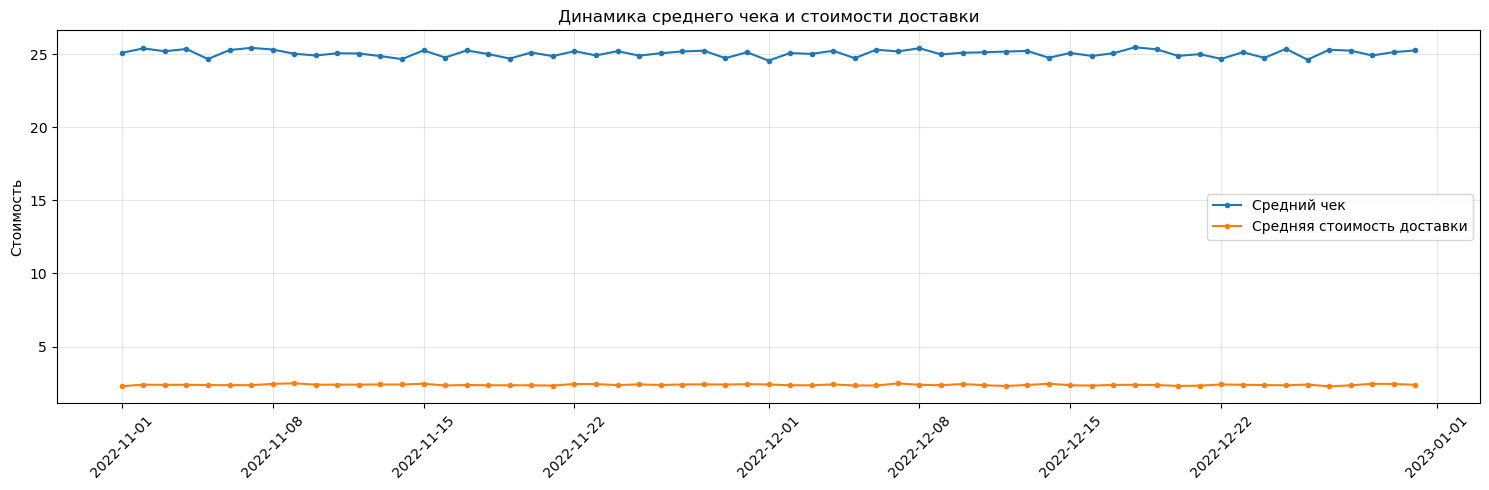

In [11]:
# Средний чек и стоимость доставки
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily_metrics['order_date'], daily_metrics['avg_order_value'], label='Средний чек', marker='.')
ax.plot(daily_metrics['order_date'], daily_metrics['avg_delivery_fee'], label='Средняя стоимость доставки', marker='.')
ax.set_title('Динамика среднего чека и стоимости доставки')
ax.set_ylabel('Стоимость')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [12]:
daily_metrics.head()

,order_date,total_orders,delivered_orders,cancelled_orders,avg_delivery_time,median_delivery_time,avg_order_value,avg_delivery_fee,completion_rate,cancellation_rate
0,2022-11-01,1009,963,46,31.517445,30.1,25.091615,2.284965,0.954410,0.045590
1,2022-11-02,993,952,41,31.725630,29.6,25.404552,2.390564,0.958711,0.041289
2,2022-11-03,992,925,67,34.353622,32.7,25.205383,2.375252,0.932460,0.067540
3,2022-11-04,1535,1463,72,31.755707,30.0,25.361316,2.384384,0.953094,0.046906
4,2022-11-05,1514,1446,68,30.828907,28.7,24.674485,2.358448,0.955086,0.044914


Явного долгосрочного тренда нет, но заметна недельная сезонность (пики в конце недели), при этом амплитуда растет к концу декабря. Средний чек и стоимость доставки стабильны весь период

**Подозрительные дни**

Начало декабря: провал Completion Rate, рост отмен. Если посмотреть на график с динамикой времени доставки, появились долгие заказы

Середина декабря: снова падение Completion Rate и максимум времени доставки.

Конец декабря: опять провал Completion Rate и рост отмен, среднее и медианное время растут синхронно

#### 2. Выявление аномалий — 3 балла
Проверьте построенные дневные ряды следующих метрик на аномальность:
- Число заказов, число доставленных заказов;
- Completion Rate, Cancellation Rate;
- Время доставки (среднее и медиана).

Для метрик, в которых визуально заметна недельная сезонность (абсолютные метрики), используйте STL-разложение + 3σ, для других — просто 3σ (вы проводите ретроспективный анализ, а не имитируете онлайн-проверку, не забывайте об этом в реализации).

Дайте короткий комментарий по результатам проверки.

In [13]:
# your code is here
def find_anomalies_stl(series, period=7, sigma=3):
# STL + 3сигма на остатках. Ретроспективно: mean/std остатков по всему ряду
    series = series.copy()
    series.index = pd.to_datetime(series.index)
    stl = STL(series, period=period, robust=True)
    result = stl.fit()
    resid = result.resid
    lower = resid.mean() - sigma*resid.std()
    upper = resid.mean() + sigma*resid.std()
    anomalies = series[(resid < lower) | (resid > upper)]
    return anomalies

In [14]:
def find_anomalies_3sigma(series, sigma=3):
# Ретроспективный 3сигма, т.е. mean/std по всему ряду
    series = series.copy()
    series.index = pd.to_datetime(series.index)
    lower = series.mean() - sigma*series.std()
    upper = series.mean() + sigma*series.std()
    anomalies = series[(series < lower) | (series > upper)]
    return anomalies

In [15]:
daily_ts = daily_metrics.set_index('order_date')

In [16]:
print("Аномалии: общее число заказов (STL)\n", find_anomalies_stl(daily_ts['total_orders']))
print("\nАномалии: доставленные заказы (STL)\n", find_anomalies_stl(daily_ts['delivered_orders']))
print("\nАномалии: Completion Rate (3сигма)\n", find_anomalies_3sigma(daily_ts['completion_rate']))
print("\nАномалии: Cancellation Rate (3сигма)\n", find_anomalies_3sigma(daily_ts['cancellation_rate']))
print("\nАномалии: среднее время доставки (3сигма)\n", find_anomalies_3sigma(daily_ts['avg_delivery_time']))
print("\nАномалии: медианное время доставки (3сигма)\n", find_anomalies_3sigma(daily_ts['median_delivery_time']))

Аномалии: общее число заказов (STL)
 order_date
2022-12-03    1375
Name: total_orders, dtype: int64

Аномалии: доставленные заказы (STL)
 order_date
2022-12-03    1310
2022-12-27    1057
Name: delivered_orders, dtype: int64

Аномалии: Completion Rate (3сигма)
 order_date
2022-12-13    0.767072
Name: completion_rate, dtype: float64

Аномалии: Cancellation Rate (3сигма)
 order_date
2022-12-13    0.232928
Name: cancellation_rate, dtype: float64

Аномалии: среднее время доставки (3сигма)
 order_date
2022-12-13    58.949268
Name: avg_delivery_time, dtype: float64

Аномалии: медианное время доставки (3сигма)
 order_date
2022-12-13    58.0
Name: median_delivery_time, dtype: float64


По STL аномалии в числе заказов и доставок 3 и 27 декабря (возможно сезонные колебания спроса).

По 3сигма все четыре метрики показали аномалию в один день 13 декабря

Еще среднее и медиана времени аномальны одновременно, видимо 13 декабря проблема не в отдельных выбросах

Надо обязательно посмотреть 13 декабря!

#### 3. Поиск причин аномального поведения (шаг 1) — 3 балла
Разложим метрики, в которых обнаружены аномалии, на составляющие.

Визуализируйте:
- Отмены в разрезе причин (абсолютная метрика);
- Длительность этапов, из которых складывается итоговая продолжительность доставки (time_to_assign_courier_min, actual_preparation_time_min, travel_time_min). Берите среднее или медиану на ваш выбор.

Есть ли какие-нибудь закономерности?

In [17]:
# your code is here
# 1. Отмены по причинам
cancelled_df = df[df['status'] == 'cancelled']
cancellations_by_reason = cancelled_df.groupby(['order_date', 'cancellation_reason']).size().unstack(fill_value=0)

In [18]:
cancellations_by_reason.info()

<class 'pandas.core.frame.DataFrame'>
Index: 61 entries, 2022-11-01 to 2022-12-31
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Cancelled by user     61 non-null     int64
 1   No courier available  61 non-null     int64
dtypes: int64(2)
memory usage: 1.4+ KB


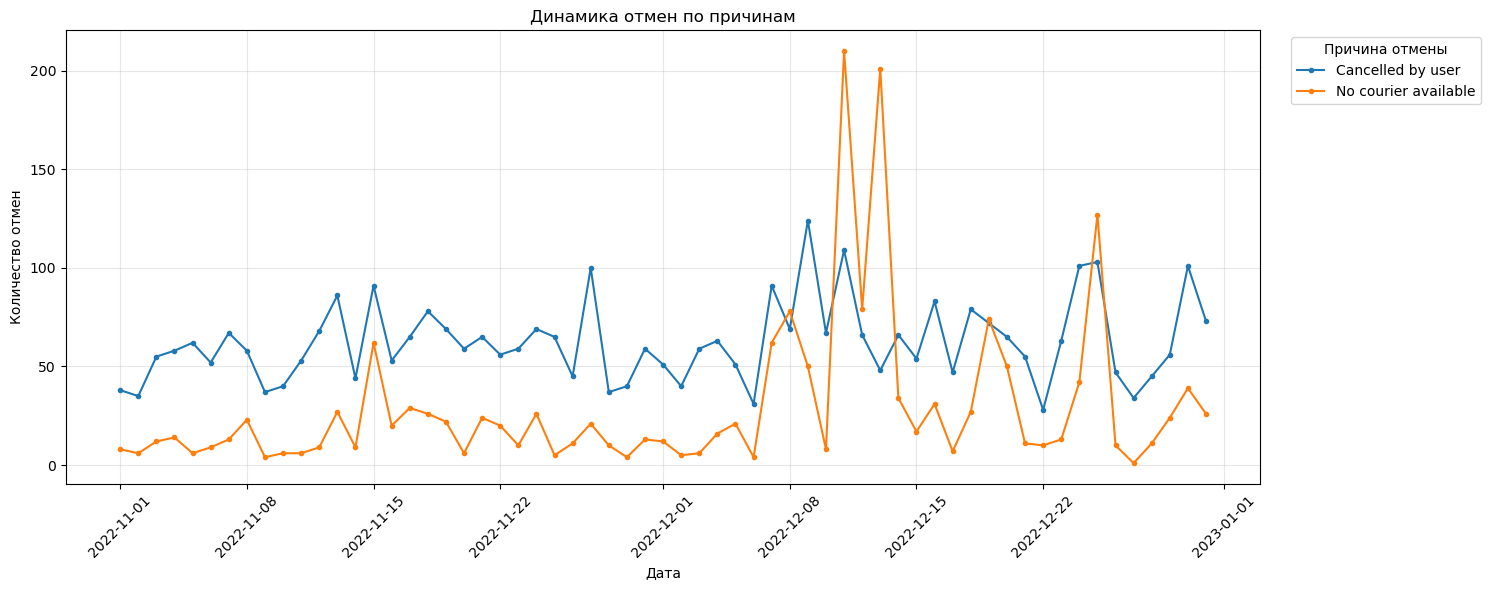

In [19]:
fig, ax = plt.subplots(figsize=(15, 6))
cancellations_by_reason.plot(kind='line', ax=ax, marker='o', markersize=3, linewidth=1.5)
ax.set_title('Динамика отмен по причинам')
ax.set_ylabel('Количество отмен')
ax.set_xlabel('Дата')
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Причина отмены', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

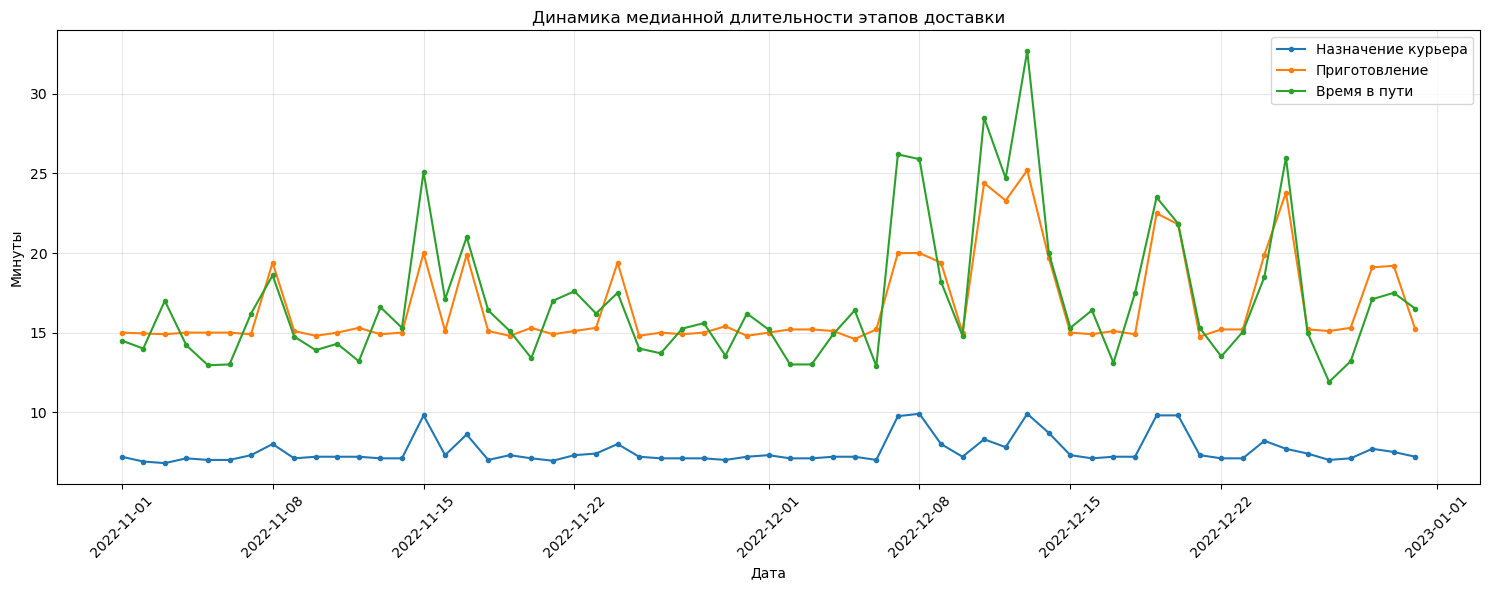

In [20]:
# 2. Этапы доставки, возьму медиану, так как она устойчевее к выбросам
stage_durations = df.groupby('order_date').agg(
    median_assign_time=('time_to_assign_courier_min', 'median'),
    median_prep_time=('actual_preparation_time_min', 'median'),
    median_travel_time=('travel_time_min', 'median')
).reset_index()

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(stage_durations['order_date'], stage_durations['median_assign_time'], label='Назначение курьера', marker='.')
ax.plot(stage_durations['order_date'], stage_durations['median_prep_time'], label='Приготовление', marker='.')
ax.plot(stage_durations['order_date'], stage_durations['median_travel_time'], label='Время в пути', marker='.')
ax.set_title('Динамика медианной длительности этапов доставки')
ax.set_ylabel('Минуты')
ax.set_xlabel('Дата')
ax.tick_params(axis='x', rotation=45)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

1. Причины. В аномальные дни (особенно 13 декабря) резко растут отмены по причине "No courier available". Отмены пользователей тоже растут, но меньше.

2.  Этапы. Время назначения курьера низкое, а вот приготовление и время в пути в середине декабря очень сильно растут

Те все-таки проблема не в нехватке курьеров, а в замедлении на стороне ресторанов и на дороге. Из-за этого курьеры позже освобождаются и причине нет курьера. Предполагаю, так как это зимнее время, проблема может быть в погоде



#### 4. Поиск причин аномального поведения (шаг 2) — 3 балла
Постройте динамику метрик, в которых обнаружены аномалии, по базовым срезам (можете выбрать что-то одно: Completion Rate или Cancellation Rate, среднее время доставки или медиана времени доставки):
- платформа (iOS, Android);
- район адреса доставки;
- сегмент пользователя (новые/повторные);
- признак промо акции.

Выделяется ли какой-то сегмент, где аномалия выражена сильнее?

In [21]:
# your code is here
# Срезы
slices = ['platform', 'city_region', 'user_segment', 'promotion_used']

Cancellation Rate

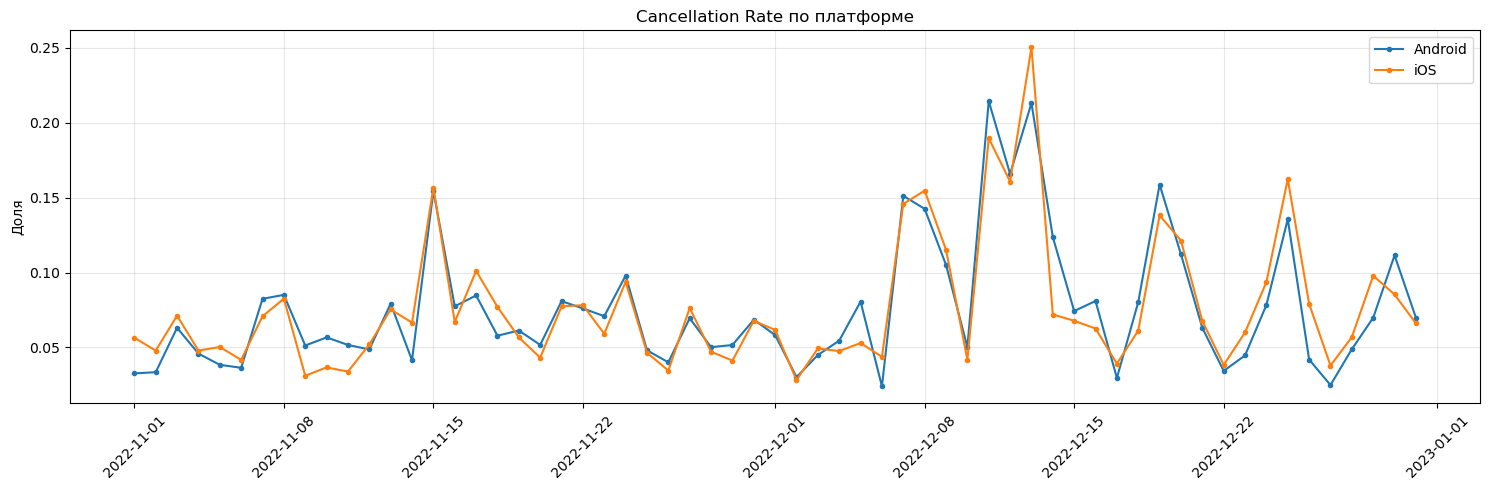

In [22]:
# платформа
agg = df.groupby(['order_date', 'platform']).agg(
    cancelled=('status', lambda x: (x == 'cancelled').sum()),
    total=('order_id', 'count')
).reset_index()
agg['cancellation_rate'] = agg['cancelled']/agg['total']

fig, ax = plt.subplots(figsize=(15, 5))
for cat in agg['platform'].unique():
    sub = agg[agg['platform'] == cat]
    ax.plot(sub['order_date'], sub['cancellation_rate'], label=cat, marker='.')
ax.set_title('Cancellation Rate по платформе')
ax.set_ylabel('Доля')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

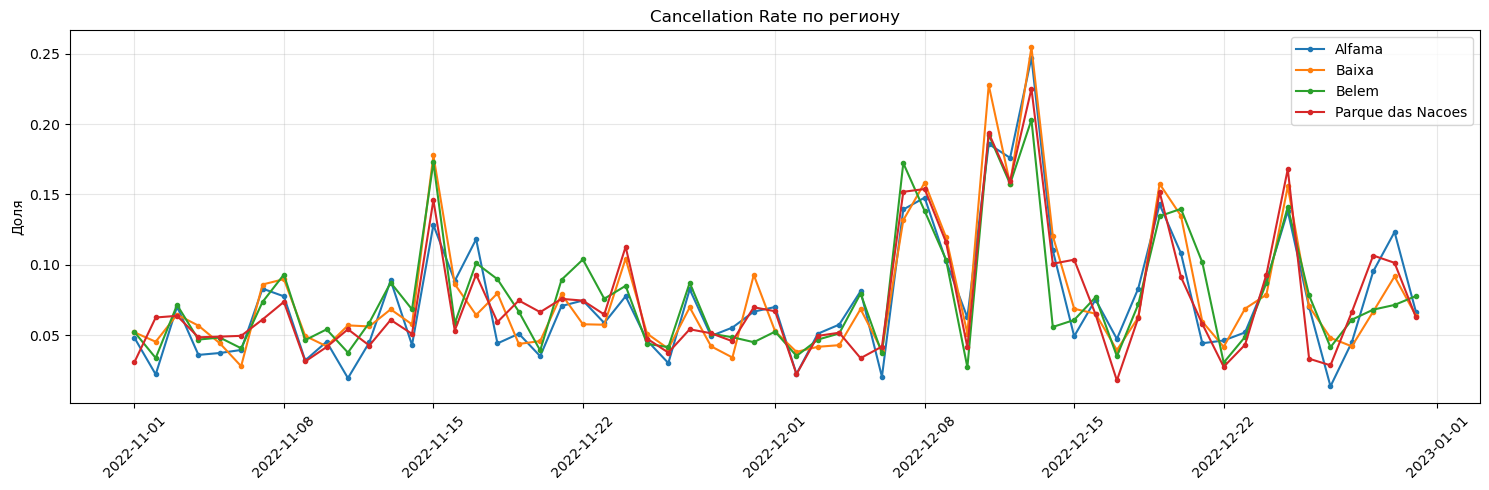

In [23]:
# по региону
agg = df.groupby(['order_date', 'city_region']).agg(
    cancelled=('status', lambda x: (x == 'cancelled').sum()),
    total=('order_id', 'count')
).reset_index()
agg['cancellation_rate'] = agg['cancelled']/agg['total']

fig, ax = plt.subplots(figsize=(15, 5))
for cat in agg['city_region'].unique():
    sub = agg[agg['city_region'] == cat]
    ax.plot(sub['order_date'], sub['cancellation_rate'], label=cat, marker='.')
ax.set_title('Cancellation Rate по региону')
ax.set_ylabel('Доля')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

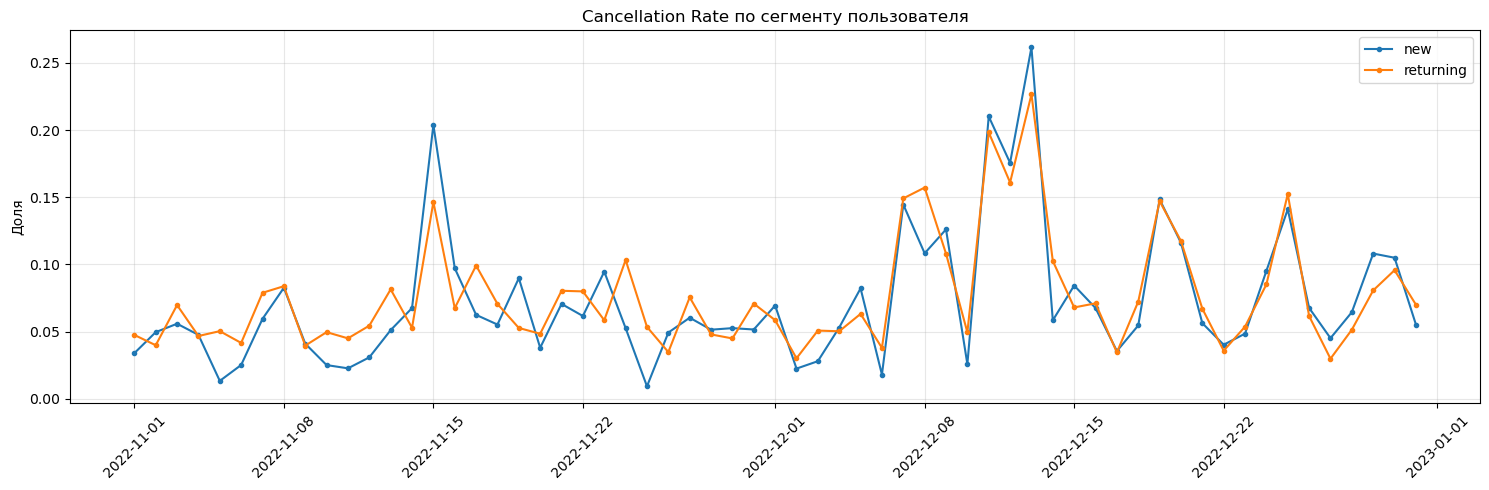

In [24]:
# по сегменту
agg = df.groupby(['order_date', 'user_segment']).agg(
    cancelled=('status', lambda x: (x == 'cancelled').sum()),
    total=('order_id', 'count')
).reset_index()
agg['cancellation_rate'] = agg['cancelled']/agg['total']

fig, ax = plt.subplots(figsize=(15, 5))
for cat in agg['user_segment'].unique():
    sub = agg[agg['user_segment'] == cat]
    ax.plot(sub['order_date'], sub['cancellation_rate'], label=cat, marker='.')
ax.set_title('Cancellation Rate по сегменту пользователя')
ax.set_ylabel('Доля')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

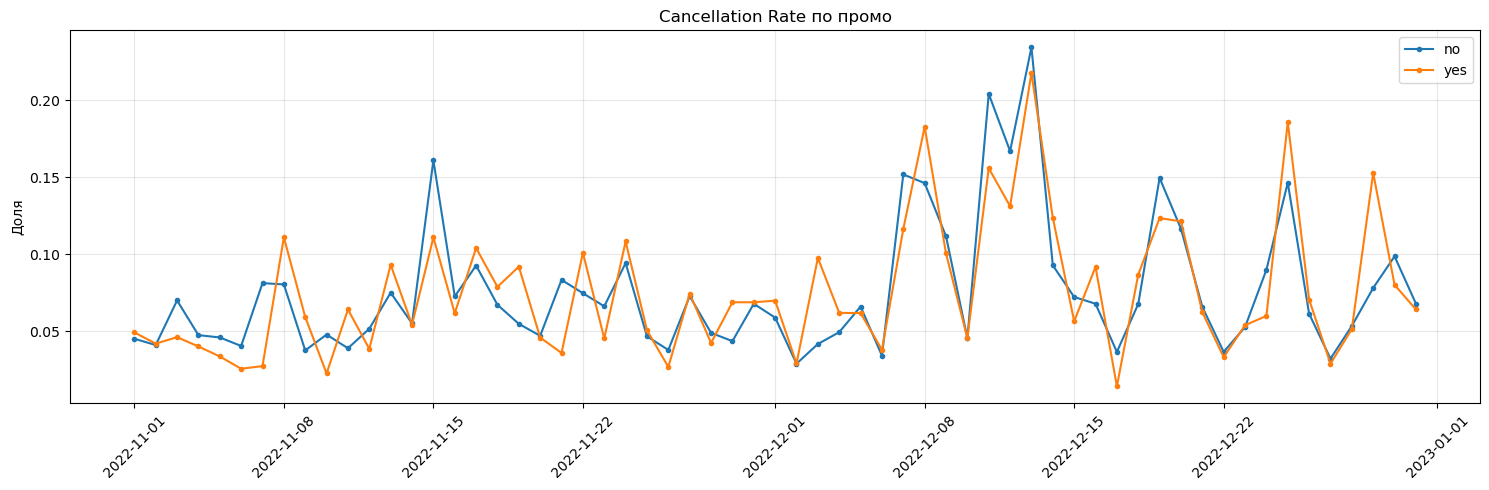

In [25]:
# по промо
agg = df.groupby(['order_date', 'promotion_used']).agg(
    cancelled=('status', lambda x: (x == 'cancelled').sum()),
    total=('order_id', 'count')
).reset_index()
agg['cancellation_rate'] = agg['cancelled']/agg['total']

fig, ax = plt.subplots(figsize=(15, 5))
for cat in agg['promotion_used'].unique():
    sub = agg[agg['promotion_used'] == cat]
    ax.plot(sub['order_date'], sub['cancellation_rate'], label=cat, marker='.')
ax.set_title('Cancellation Rate по промо')
ax.set_ylabel('Доля')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Медианное время доставки

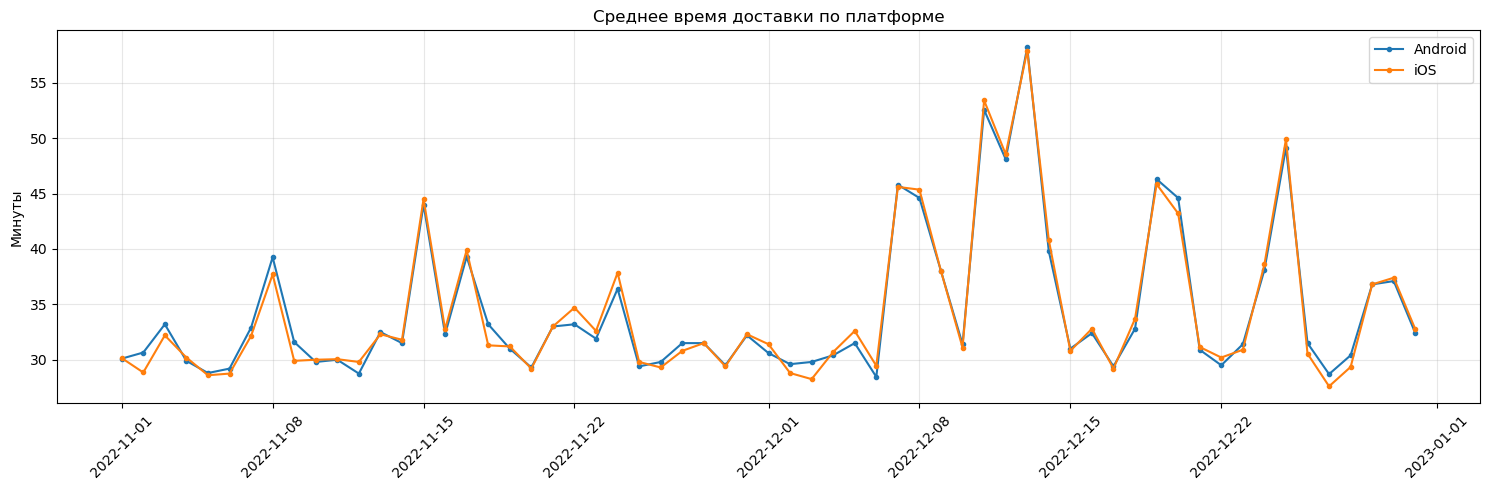

In [26]:
# платформа
agg = df.groupby(['order_date', 'platform'])['delivery_duration_min'].median().reset_index()

fig, ax = plt.subplots(figsize=(15, 5))
for cat in agg['platform'].unique():
    sub = agg[agg['platform'] == cat]
    ax.plot(sub['order_date'], sub['delivery_duration_min'], label=cat, marker='.')
ax.set_title('Среднее время доставки по платформе')
ax.set_ylabel('Минуты')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

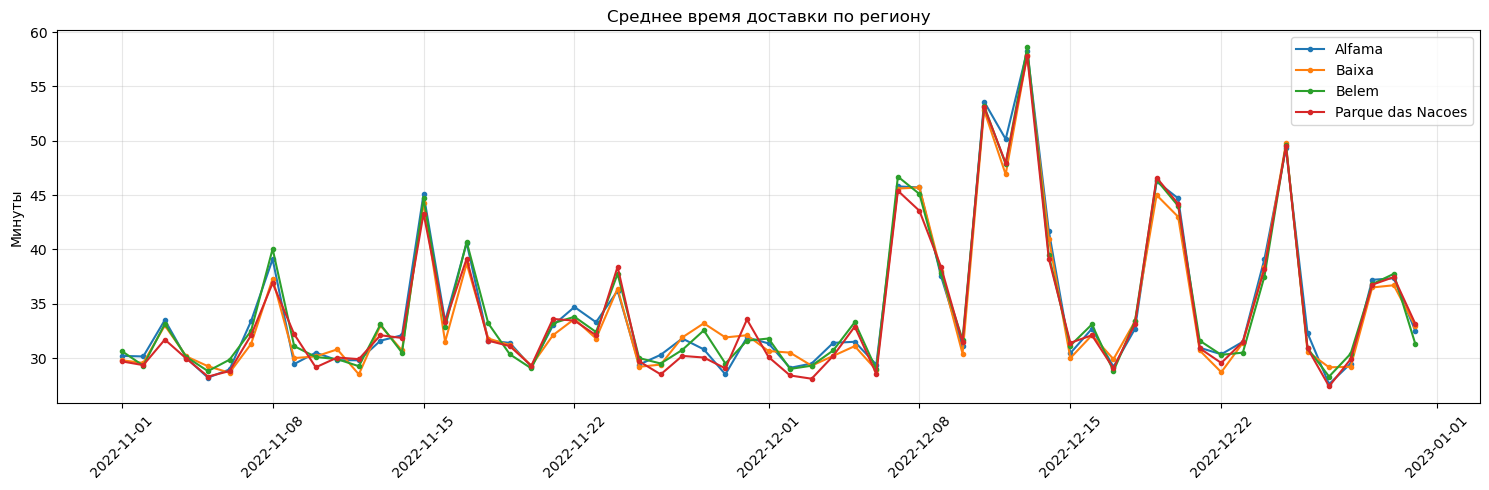

In [27]:
# регион
agg = df.groupby(['order_date', 'city_region'])['delivery_duration_min'].median().reset_index()

fig, ax = plt.subplots(figsize=(15, 5))
for cat in agg['city_region'].unique():
    sub = agg[agg['city_region'] == cat]
    ax.plot(sub['order_date'], sub['delivery_duration_min'], label=cat, marker='.')
ax.set_title('Среднее время доставки по региону')
ax.set_ylabel('Минуты')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

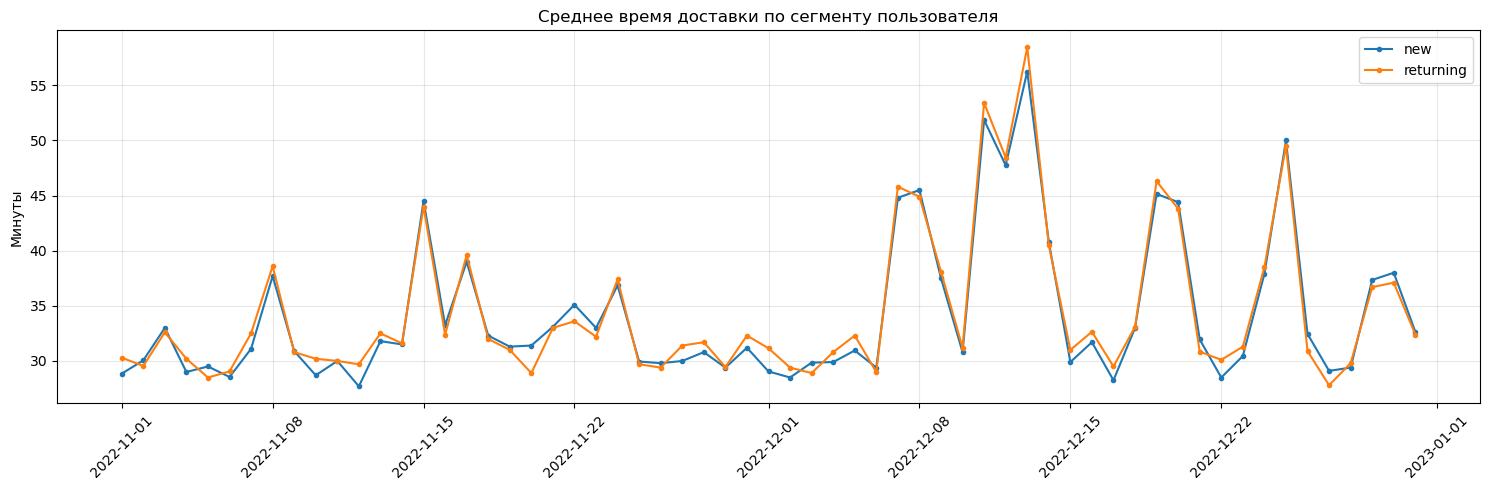

In [28]:
# сегмент
agg = df.groupby(['order_date', 'user_segment'])['delivery_duration_min'].median().reset_index()

fig, ax = plt.subplots(figsize=(15, 5))
for cat in agg['user_segment'].unique():
    sub = agg[agg['user_segment'] == cat]
    ax.plot(sub['order_date'], sub['delivery_duration_min'], label=cat, marker='.')
ax.set_title('Среднее время доставки по сегменту пользователя')
ax.set_ylabel('Минуты')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

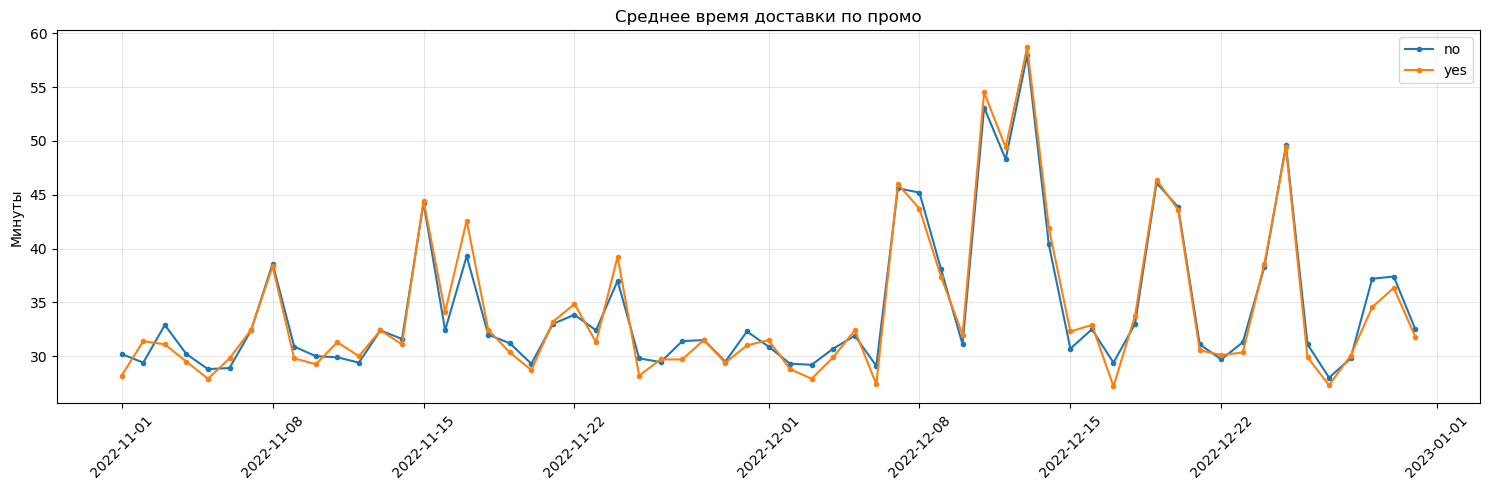

In [29]:
# промо
agg = df.groupby(['order_date', 'promotion_used'])['delivery_duration_min'].median().reset_index()

fig, ax = plt.subplots(figsize=(15, 5))
for cat in agg['promotion_used'].unique():
    sub = agg[agg['promotion_used'] == cat]
    ax.plot(sub['order_date'], sub['delivery_duration_min'], label=cat, marker='.')
ax.set_title('Среднее время доставки по промо')
ax.set_ylabel('Минуты')
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Ни один сегмент не выделяется, значит, причина не в базовых срезах

#### 5. Поиск причин аномального поведения (шаг 3) — 3 балла

Постройте динамику структуры заказов в разрезе сегментов:
- доля заказов по платформам;
- доля заказов по регионам города;
- доля заказов по сегменту пользователя;
- доля заказов по признаку промо акции.

Сравните даты аномалий с динамикой долей. Может ли изменение структуры объяснить падение метрик?

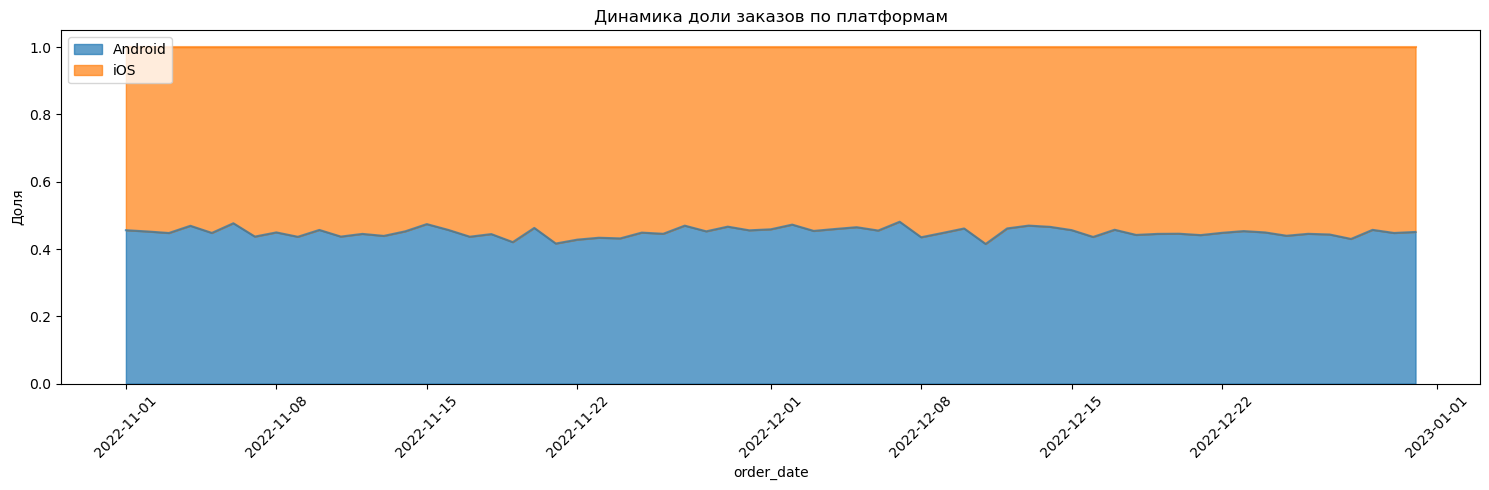

In [31]:
# your code is here
# доля по платформам
s = df.groupby(['order_date', 'platform']).size().unstack(fill_value=0)
s = s.div(s.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(15, 5))
s.plot(kind='area', stacked=True, ax=ax, alpha=0.7)
ax.set_title('Динамика доли заказов по платформам')
ax.set_ylabel('Доля')
ax.legend(loc='upper left')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

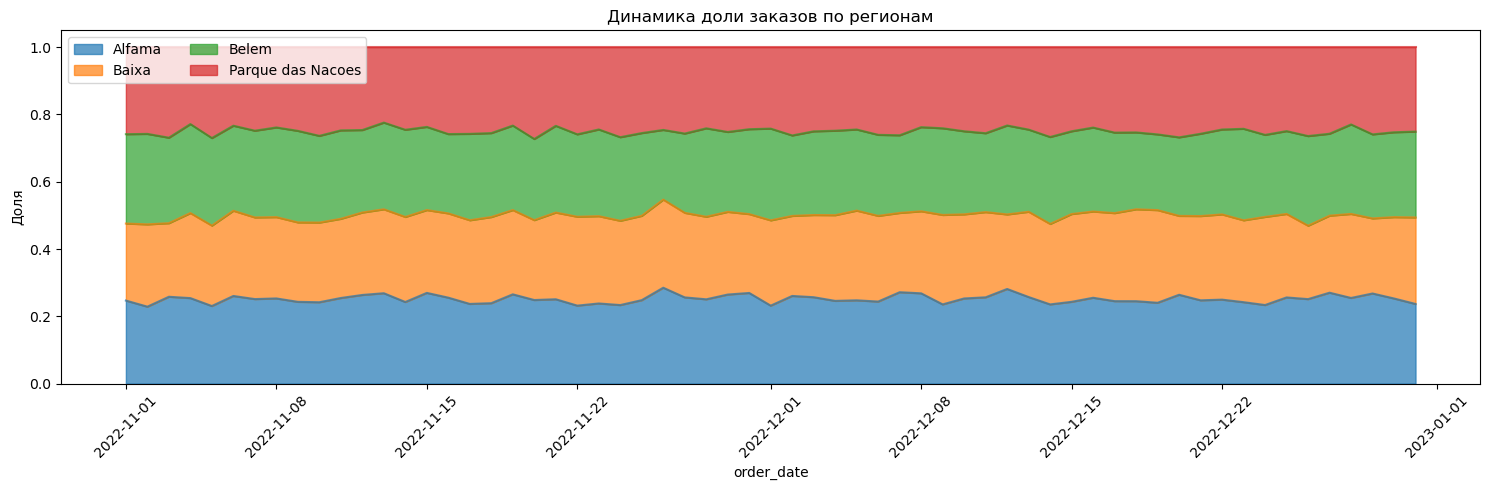

In [32]:
# доля по регионам
s = df.groupby(['order_date', 'city_region']).size().unstack(fill_value=0)
s = s.div(s.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(15, 5))
s.plot(kind='area', stacked=True, ax=ax, alpha=0.7)
ax.set_title('Динамика доли заказов по регионам')
ax.set_ylabel('Доля')
ax.legend(loc='upper left', ncol=2)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

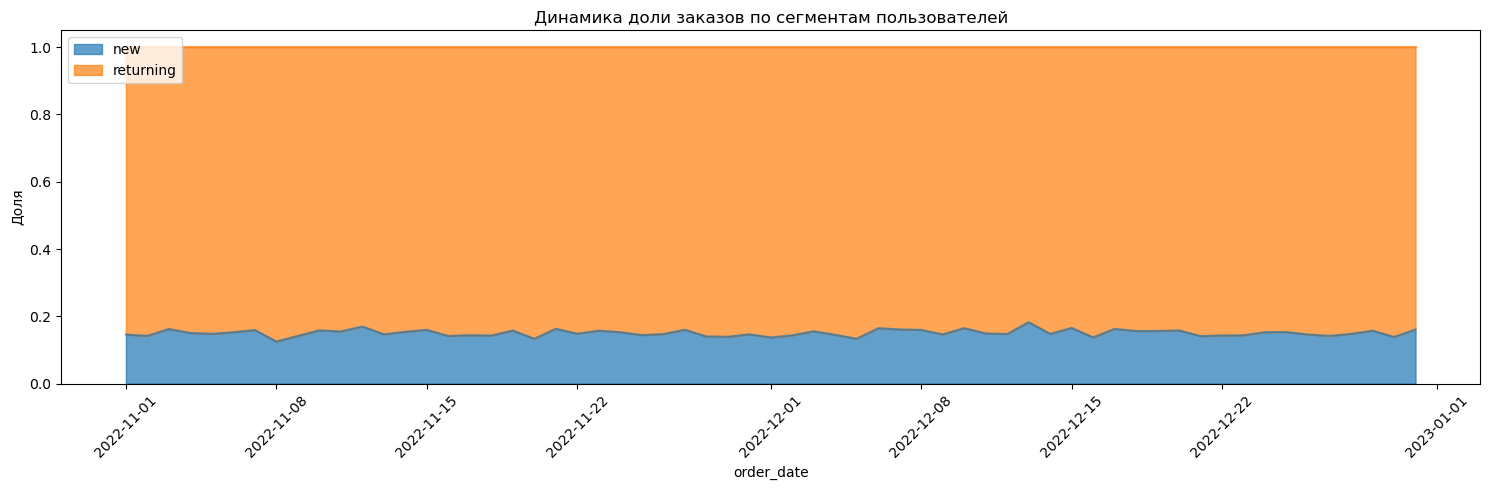

In [33]:
# доля по сегментам
s = df.groupby(['order_date', 'user_segment']).size().unstack(fill_value=0)
s = s.div(s.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(15, 5))
s.plot(kind='area', stacked=True, ax=ax, alpha=.7)
ax.set_title('Динамика доли заказов по сегментам пользователей')
ax.set_ylabel('Доля')
ax.legend(loc='upper left')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

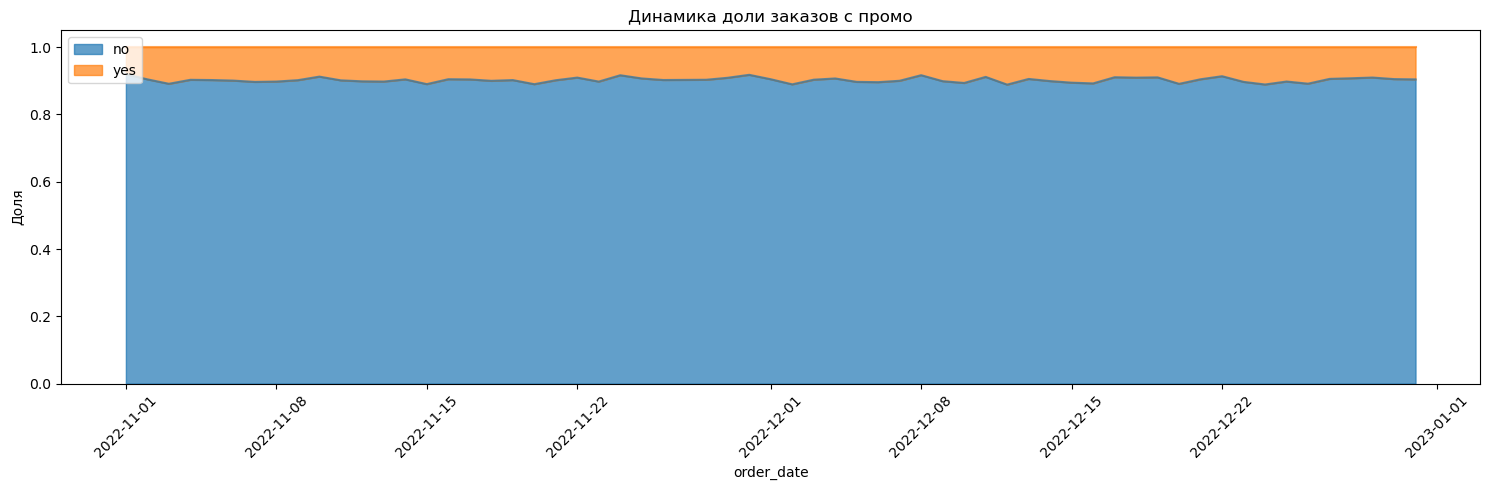

In [34]:
# доля по промо
s = df.groupby(['order_date', 'promotion_used']).size().unstack(fill_value=0)
s = s.div(s.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(15, 5))
s.plot(kind='area', stacked=True, ax=ax, alpha=0.7)
ax.set_title('Динамика доли заказов с промо')
ax.set_ylabel('Доля')
ax.legend(loc='upper left')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Изменение структуры не может объяснить падение метрик

Видимо есть какая-то внешняя проблема

#### 6. Поиск причин аномального поведения (шаг 4) — 3 балла
Разложение метрик на срезы не принесло результатов. Может быть причина аномалий лежит вне продукта?

Получите данные о погоде по API за весь анализируемый период по дням. Для этого используйте [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api?daily=temperature_2m_mean,wind_speed_10m_max,precipitation_sum) от Open-Meteo (регистрация и получение ключа не требуется, по ссылке есть пример запроса на Python).

- Для координат выгрузки возьмите: latitude: 38.736946, longitude: -9.142685;
- Timezone — auto;
- daily значения temperature_2m_mean, precipitation_sum, wind_speed_10m_max.

Соберите датасет с колонками: день, средняя температура воздуха, максимальная скорость ветра, суммарное количество осадков.

In [35]:
# your code is here
start_date = df['order_date'].min()
end_date = df['order_date'].max()

url = (
    f"https://archive-api.open-meteo.com/v1/archive?"
    f"latitude=38.736946&longitude=-9.142685&"
    f"start_date={start_date}&end_date={end_date}&"
    f"daily=temperature_2m_mean,precipitation_sum,wind_speed_10m_max&"
    f"timezone=auto"
)
weather_data = requests.get(url).json()

weather_df = pd.DataFrame({
    'date': pd.to_datetime(weather_data['daily']['time']).date,
    'temperature_mean': weather_data['daily']['temperature_2m_mean'],
    'precipitation_sum': weather_data['daily']['precipitation_sum'],
    'wind_speed_max': weather_data['daily']['wind_speed_10m_max']
})

print(weather_df.head())

         date  temperature_mean  precipitation_sum  wind_speed_max
0  2022-11-01              15.7                0.0            16.1
1  2022-11-02              14.8                0.0            14.8
2  2022-11-03              17.7                4.2            23.1
3  2022-11-04              15.6                0.0            15.5
4  2022-11-05              14.1                0.0             9.7


#### 7. Поиск причин аномального поведения (шаг 5) — 3 балла
Объедините датасет метрик, в которых найдены аномалии, с датасетом погоды.    
Для каждой метрики постройте совместные визуализации данных погоды и продуктовой метрики.

Сформулируйте гипотезу — что могло повлиять на падение конверсии в дни аномалий? Как конверсия связана с другими метриками, для которых вы  обнаружили аномальные значения? Какую роль в изменении метрик могла сыграть погода?

In [36]:
# your code is here
merged_df = daily_metrics.merge(weather_df, left_on='order_date', right_on='date', how='left')
merged_df = merged_df.drop(columns=['date']).set_index('order_date')

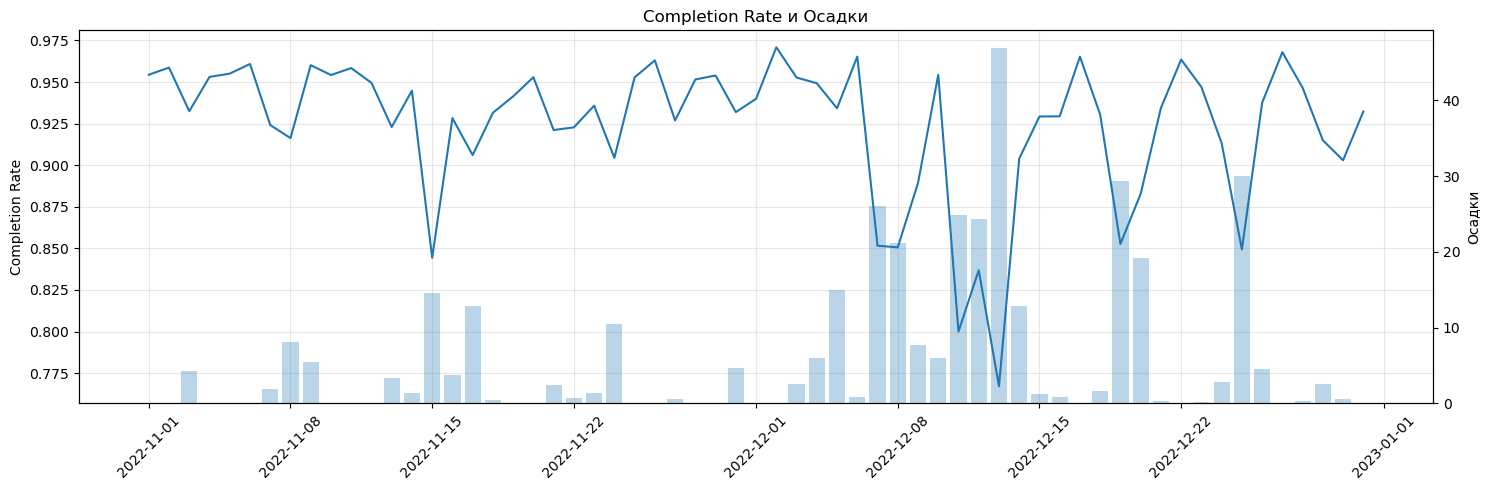

In [37]:
# completion и осадки
fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(merged_df.index, merged_df['completion_rate'], label='Completion Rate')
ax1.set_ylabel('Completion Rate')
ax1.tick_params(axis='y')
ax1.grid(True, alpha=0.3)

ax1_twin = ax1.twinx()
ax1_twin.bar(merged_df.index, merged_df['precipitation_sum'], alpha=0.3)
ax1_twin.set_ylabel('Осадки')
ax1.set_title('Completion Rate и Осадки')
ax1.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

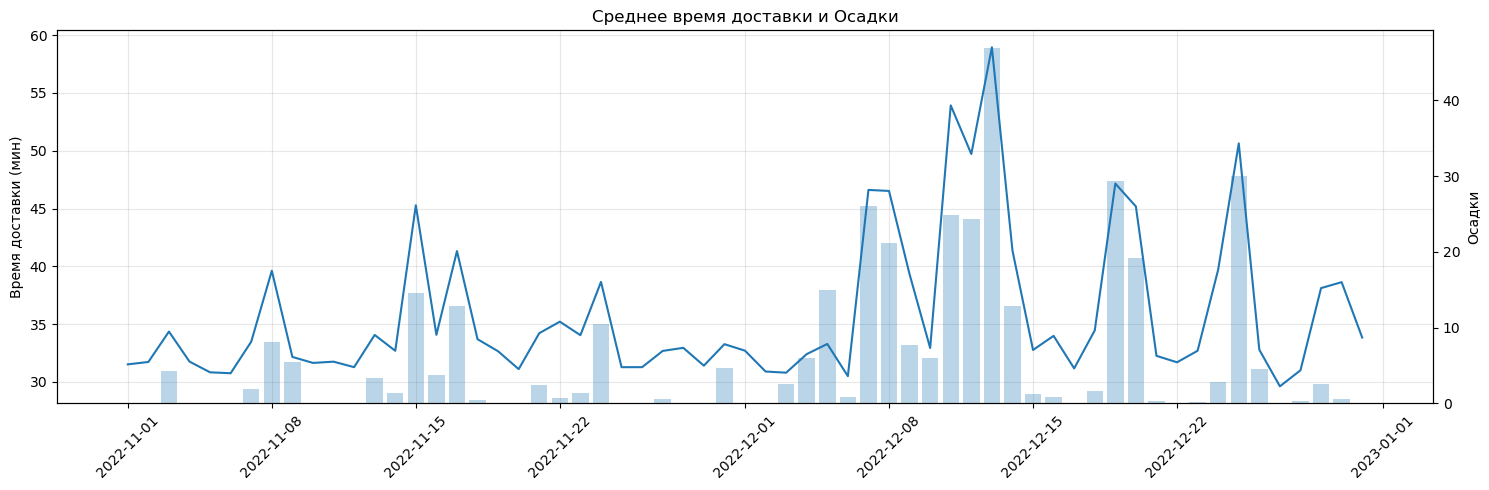

In [38]:
# среднее время доставки и осадки
fig, ax2 = plt.subplots(figsize=(15, 5))
ax2.plot(merged_df.index, merged_df['avg_delivery_time'], label='Среднее время')
ax2.set_ylabel('Время доставки (мин)')
ax2.tick_params(axis='y')
ax2.grid(True, alpha=0.3)

ax2_twin = ax2.twinx()
ax2_twin.bar(merged_df.index, merged_df['precipitation_sum'], alpha=0.3)
ax2_twin.set_ylabel('Осадки')
ax2.set_title('Среднее время доставки и Осадки')
ax2.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

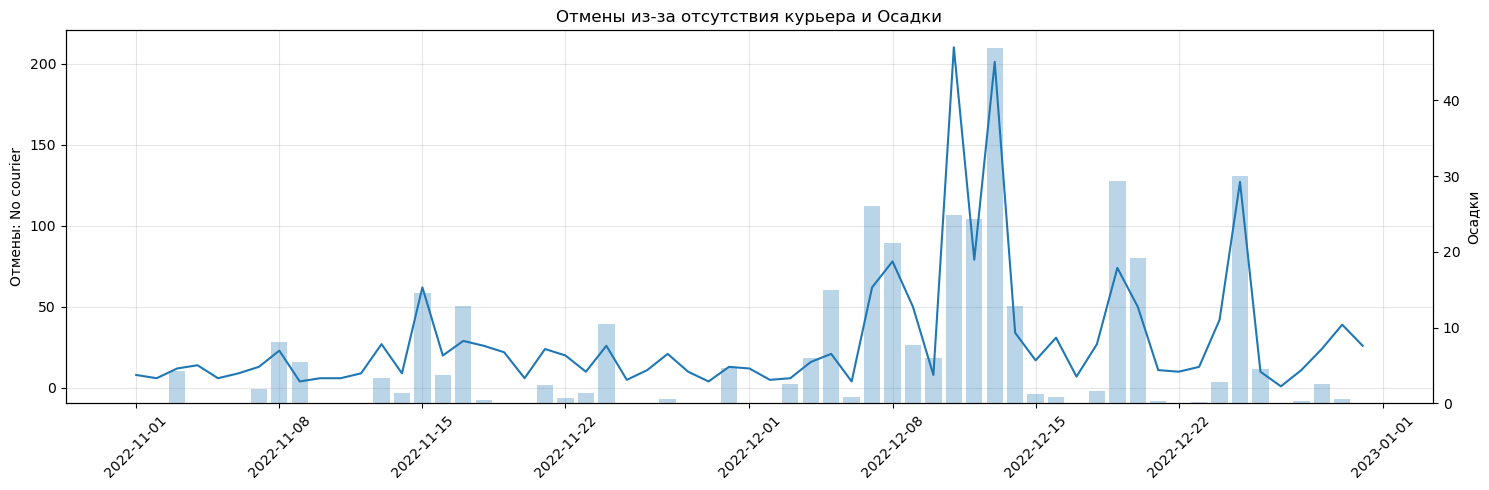

In [39]:
# отмены из-за отчуствия курьера и осадки
cancellations_aligned = cancellations_by_reason.reindex(merged_df.index).fillna(0)

fig, ax3 = plt.subplots(figsize=(15, 5))
ax3.plot(cancellations_aligned.index, cancellations_aligned['No courier available'])
ax3.set_ylabel('Отмены: No courier')
ax3.tick_params(axis='y')
ax3.grid(True, alpha=0.3)

ax3_twin = ax3.twinx()
ax3_twin.bar(merged_df.index, merged_df['precipitation_sum'], alpha=0.3)
ax3_twin.set_ylabel('Осадки')
ax3.set_title('Отмены из-за отсутствия курьера и Осадки')
ax3.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

На графиках видно, что когда осадки, падает Completion Rate, растет время доставки и резко прыгают отмены нет курьера, по датам совпадает

Тут может быть такая причино-следственная связь: осадки, из-за этого курьеры не выходят и/или едут медленнее, заказы долго некому везти, поэтому время доставки растет, пользователи тоже могут отменять. В итоге конверсия падает

#### 8. Влияние на бизнес-результат — 3 балла
Примените один из методов декомпозиции из разобранных в первом семинаре, чтобы оценить вклад изменения конверсии и числа заказов в изменение числа доставок в декабре относительно ноября (MoM анализ).    

Постройте waterfall диаграмму.

Выпишите дни, которые внесли наибольший вклад в падение среднемесячной конверсии декабря относительно ноября. Пересекаются ли эти даты с датами повышенного числа осадков? Сделайте выводы.

In [40]:
# your code is here
# Месячные метрики
df['month'] = df['order_time'].dt.month
monthly_metrics = df.groupby('month').agg(
    total_orders=('order_id', 'count'),
    delivered_orders=('status', lambda x: (x == 'delivered').sum())
).reset_index()
monthly_metrics['completion_rate'] = monthly_metrics['delivered_orders']/monthly_metrics['total_orders']

nov = monthly_metrics[monthly_metrics['month'] == 11].iloc[0]
dec = monthly_metrics[monthly_metrics['month'] == 12].iloc[0]

In [41]:
# Conjugate decomposition
cr_contribution_conj = nov['total_orders'] * (dec['completion_rate'] - nov['completion_rate'])
orders_contribution_conj = nov['completion_rate'] * (dec['total_orders'] - nov['total_orders'])
interaction_contribution_conj = (dec['total_orders'] - nov['total_orders']) * (dec['completion_rate'] - nov['completion_rate'])

delivered_lag = round(nov['delivered_orders'], 2)
cr_contrib = round(cr_contribution_conj, 2)
orders_contrib = round(orders_contribution_conj, 2)
interaction_contrib = round(interaction_contribution_conj, 2)
delivered_curr = round(delivered_lag + cr_contrib + orders_contrib + interaction_contrib, 2)

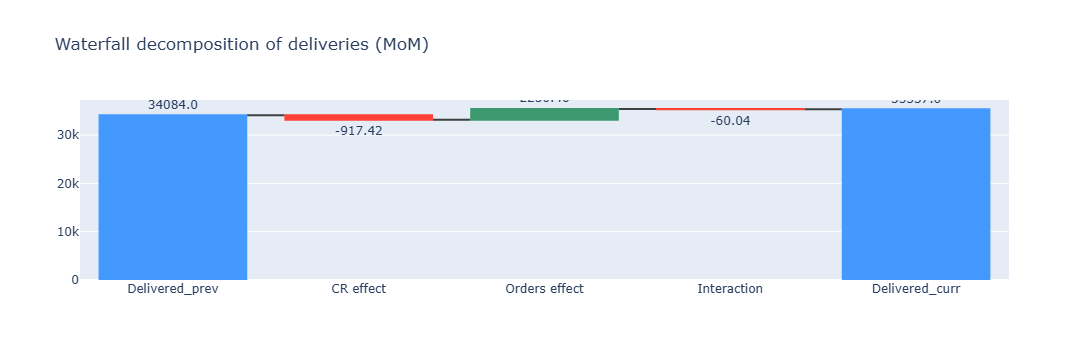

In [42]:
# Waterfall
fig = go.Figure(go.Waterfall(
    name = 'Deliveries decomposition',
    orientation = 'v',
    measure = ['absolute', 'relative', 'relative', 'relative', 'total'],
    x = ['Delivered_prev', 'CR effect', 'Orders effect', 'Interaction', 'Delivered_curr'],
    textposition = 'outside',
    text = [delivered_lag, cr_contrib, orders_contrib, interaction_contrib, delivered_curr],
    y = [delivered_lag, cr_contrib, orders_contrib, interaction_contrib, delivered_curr],
    connector = {'line':{'color': 'rgb(63, 63, 63)'}}
))
fig.update_layout(title='Waterfall decomposition of deliveries (MoM)')
fig.show()

In [43]:
# Дни с наибольшим падением конверсии в декабре
weather_df['date'] = pd.to_datetime(weather_df['date'])

dec_daily = daily_metrics.copy()
dec_daily['order_date'] = pd.to_datetime(dec_daily['order_date'])
dec_daily = dec_daily[dec_daily['order_date'].dt.month == 12]

dec_daily = dec_daily.merge(weather_df, left_on='order_date', right_on='date', how='left')
dec_daily['cr_deviation'] = dec_daily['completion_rate'] - dec['completion_rate']

worst_days = dec_daily.nsmallest(5, 'cr_deviation')[['order_date', 'completion_rate', 'cr_deviation', 'precipitation_sum']]
print(worst_days)

   order_date  completion_rate  cr_deviation  precipitation_sum
12 2022-12-13         0.767072     -0.146406               46.9
10 2022-12-11         0.800000     -0.113478               24.9
11 2022-12-12         0.836895     -0.076583               24.3
24 2022-12-25         0.849378     -0.064101               30.0
7  2022-12-08         0.850610     -0.062869               21.1


Дни с наибольшим падением конверсии в декабре: 13, 11, 12, 25, 8 декабря

Все эти дни с заметными осадками. Особенно выделяется 13 декабря

Вывод: дни с наибольшим вкладом в падение конверсии декабря - это дни с повышенным числом осадков. Это подтверждает гипотезу, что плохая погода ведет к проблемам с курьерами, следовательно к отменам и падению Completion Rate

####  9. Анализ 24/7 — 3 балла

Одним из распространенных разрезов анализа метрик продуктов с внутринедельной сезонностью является разложение по дням недели и часам. 

Постройте матрицу 24/7 (часы - дни недели) для ноября и декабря (в ячейку матрицы должно попасть агрегированное значение метрики для дня недели и часа), но перед этим очистите декабрьские значения от аномалий — для стабильной оценки нам нужны метрики без влияния экстремальной погоды.

Визуализацию стройте для:
- Числа заказов (всех);
- Completion Rate;
- Среднего или медианного времени доставки.

Подумайте, почему в определенные часы/дни недели мы наблюдаем падение конверсии? Как меняются остальные метрики?    
При ответе опирайтесь на статистические понятия — в какие-то часы просадка или, напротив, слишком высокая конверсия может быть не закономерностью, а случайностью из-за эффекта низкой базы в это время.

In [44]:
# your code is here
# Ноябрь и очищенный декабрь
nov = df[df['order_time'].dt.month == 11]
dec_clean = df[(df['order_time'].dt.month == 12) & (~df['order_date'].isin(worst_days['order_date']))]

# Добавим час и день недели
for d in [nov, dec_clean]:
    d['hour'] = d['order_time'].dt.hour
    d['weekday'] = d['order_time'].dt.weekday

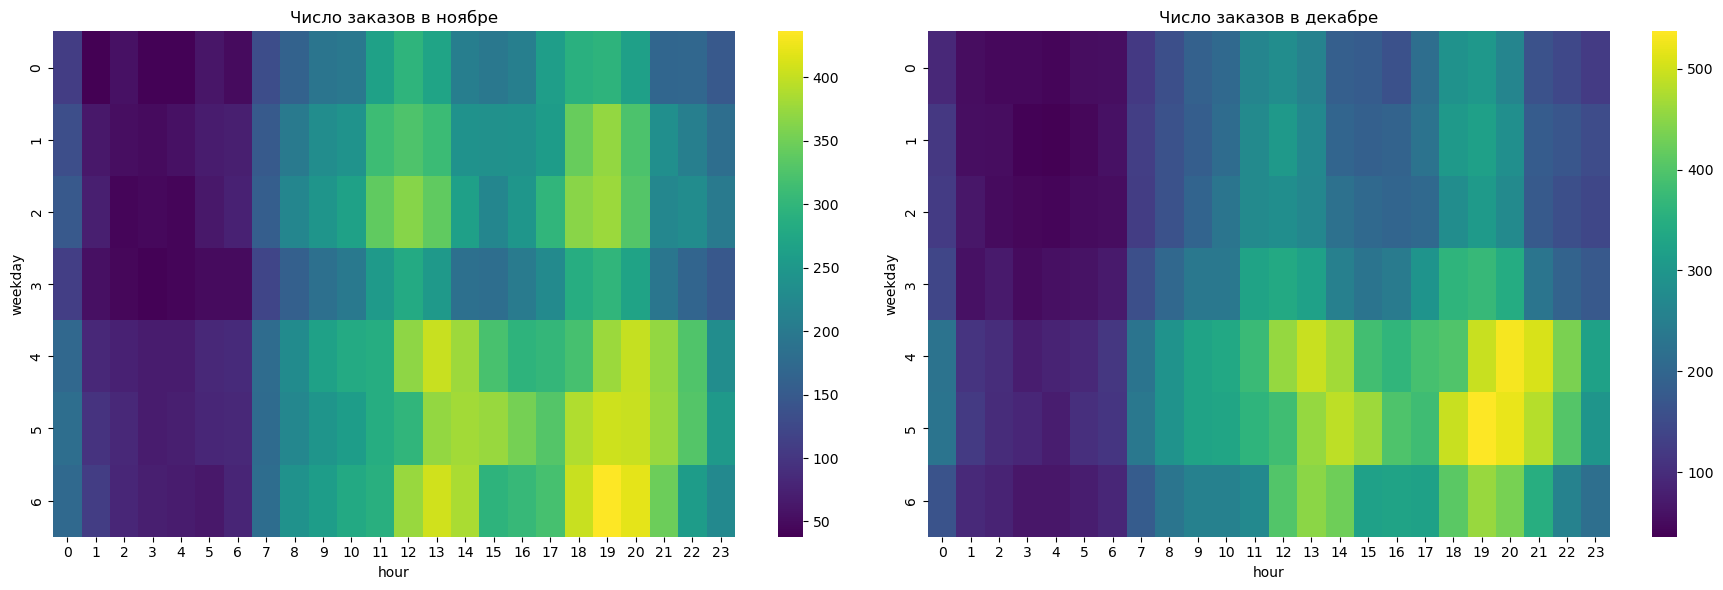

In [45]:
# Число заказов
nov_orders = nov.pivot_table(index='weekday', columns='hour', values='order_id', aggfunc='count')
dec_orders = dec_clean.pivot_table(index='weekday', columns='hour', values='order_id', aggfunc='count')

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.heatmap(nov_orders, ax=axes[0], cmap='viridis')
axes[0].set_title('Число заказов в ноябре')
sns.heatmap(dec_orders, ax=axes[1], cmap='viridis')
axes[1].set_title('Число заказов в декабре')
plt.tight_layout()
plt.show()

Видна сезонность: пики в обед (12-14) и вечер (18-21), особенно в пятницу, субботу и воскресенье. Ночью и рано утром заказов почти нет, темные ячейки. В декабре примерно так же

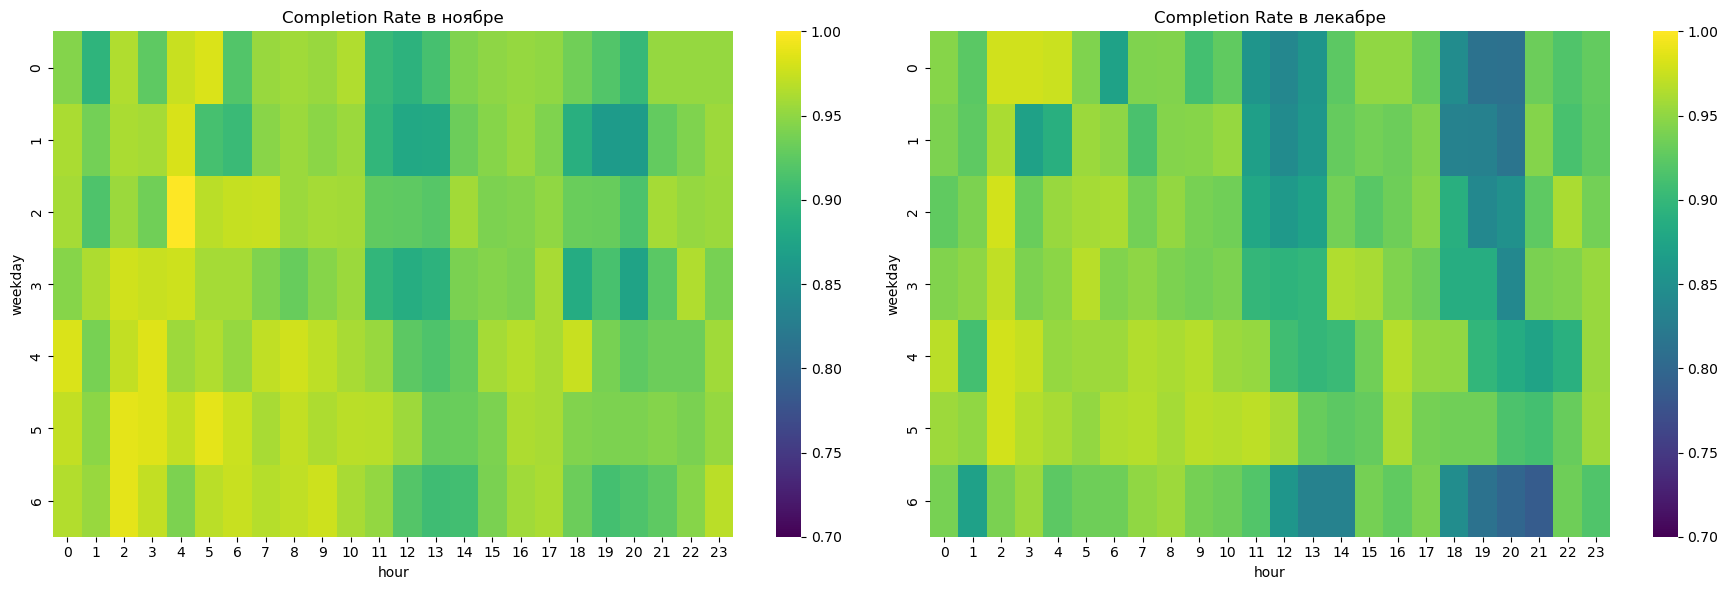

In [46]:
# Completion Rate
nov['is_delivered'] = (nov['status'] == 'delivered').astype(int)
dec_clean['is_delivered'] = (dec_clean['status'] == 'delivered').astype(int)

nov_cr = nov.pivot_table(index='weekday', columns='hour', values='is_delivered', aggfunc='mean')
dec_cr = dec_clean.pivot_table(index='weekday', columns='hour', values='is_delivered', aggfunc='mean')

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.heatmap(nov_cr, ax=axes[0], cmap='viridis', vmin=0.7, vmax=1)
axes[0].set_title('Completion Rate в ноябре')
sns.heatmap(dec_cr, ax=axes[1], cmap='viridis', vmin=0.7, vmax=1)
axes[1].set_title('Completion Rate в лекабре')
plt.tight_layout()
plt.show()

В часы пик (обед, вечер) конверсия ниже, тк система перегружена: много заказов, курьеров не хватает. В спокойные часы (ночь, утро) конверсия выше.

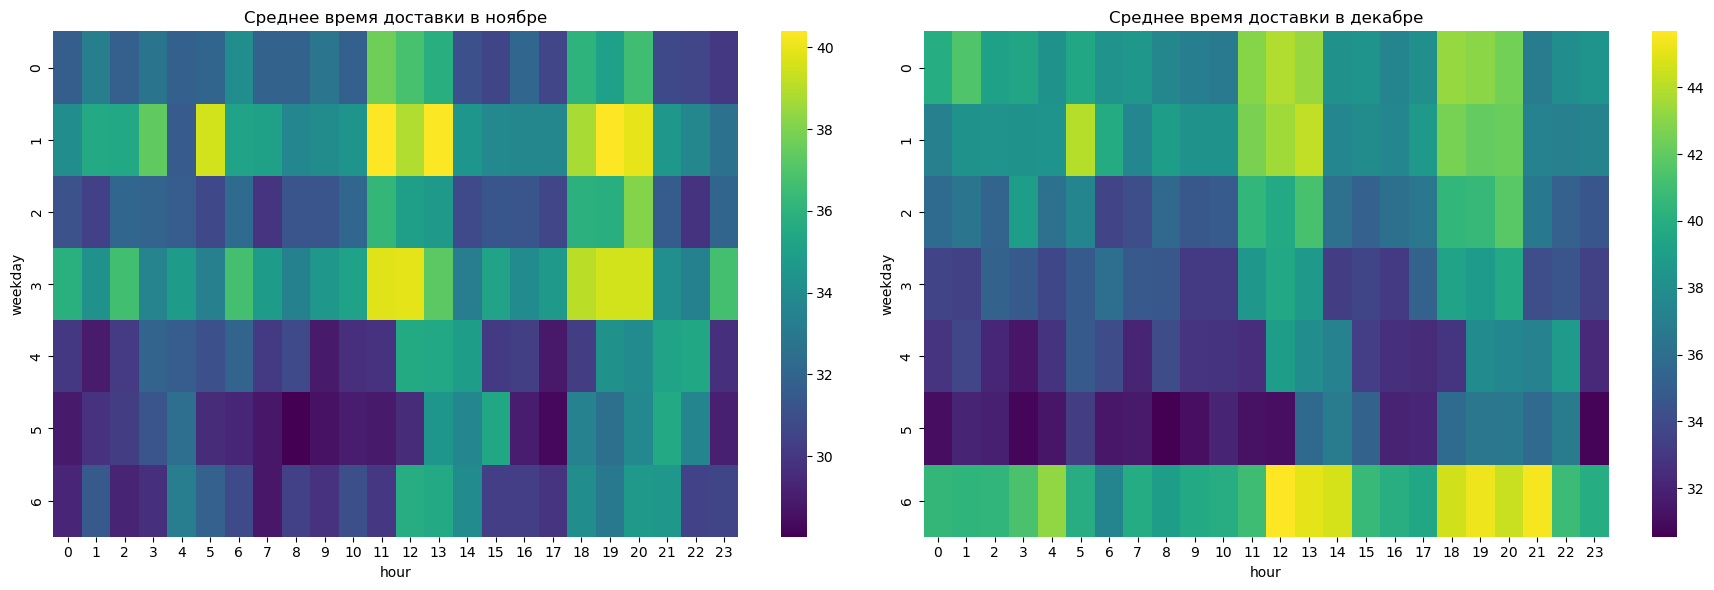

In [47]:
# Среднее время доставки
nov_time = nov.pivot_table(index='weekday', columns='hour', values='delivery_duration_min', aggfunc='mean')
dec_time = dec_clean.pivot_table(index='weekday', columns='hour', values='delivery_duration_min', aggfunc='mean')

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.heatmap(nov_time, ax=axes[0], cmap='viridis')
axes[0].set_title('Среднее время доставки в ноябре')
sns.heatmap(dec_time, ax=axes[1], cmap='viridis')
axes[1].set_title('Среднее время доставки в декабре')
plt.tight_layout()
plt.show()

В часы пик оно растет, это и объясняет падение конверсии. В выходные (сб, вс) вечером время доставки особенно большое. В декабре картина похожая

Про случайность и низкую базу. В ночные и ранние утренние часы заказов очень мало. Поэтому там конверсия может скакать, то высокая, то низкая из-за маленькой выборки. Это скорее статистическая случайность. Я бы на такие ячейки сильно не смотрела. А вот в часы пик (много заказов) просадка конверсии - это уже реальная закономерность

####   10. Предложение по улучшению продукта — 3 балла
Базовым подходом для оптимизации работы в часы пик в доставке является динамическое ценообразование. В продукте эта механика еще не реализована. Вы смотрите на данные и решаете, что это отличная инициатива для планирования следующего квартала.

*Динамическое ценообразование помогает не только сглаживать часы повышенного спроса, но и регулировать работу продукта при внешних влияниях, когда пик спроса предсказать невозможно. В данном кейсе мы не рассматриваем такие решения, т.к. не стремимся написать алгоритм динамического прайсинга, а хотим провести базовое исследование проблем и поиск инициативы под быструю реализацию и тест. Поэтому в дальнейших заданиях речь идет исключительно о часах повышенного спроса, очищенных от аномалий.* 

Чтобы протестировать гипотезу, достаточно простого подхода — увеличивать стоимость доставки на фиксированный процент (например, на 20%) в определенные дни недели-часы.

- На основе построенных в предыдущем задании матриц, предложите, в какие дни недели/часы вы порекомендуете увеличить стоимость доставки.
- Для каждого месяца рассчитайте долю заказов от общего числа, который будет иметь повышенную стоимость, согласно предложенным вами правилам повышения.

In [48]:
# Среднее число заказов по дням недели и часам (ноябрь + декабрь)
avg_orders = (nov_orders + dec_orders)/2

В качестве правил повышения предлагаю 75 перцентиль

In [49]:
# Пик = часы, где заказов больше 75-го перцентиля
threshold = avg_orders.stack().quantile(0.75)
peak = avg_orders > threshold

print('Порог:', round(threshold))
for day in peak.index:
    hours = [h for h in peak.columns if peak.loc[day, h]]
    if hours:
        print(day, hours)

Порог: 308
1 [12, 18, 19]
2 [12, 18, 19]
3 [12, 18, 19]
4 [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
5 [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
6 [12, 13, 14, 16, 17, 18, 19, 20, 21]


In [50]:
# Доля заказов под наценкой в ноябре
nov_peak = 0
for _, row in nov.iterrows():
    if peak.loc[row['weekday'], row['hour']]:
        nov_peak += 1
share_nov = nov_peak/len(nov)

print(f'Ноябрь: {share_nov:.1%}')

Ноябрь: 40.9%


In [51]:
# Доля заказов под наценкой в декабре (без аномалий)
dec_peak = 0
for _, row in dec_clean.iterrows():
    if peak.loc[row['weekday'], row['hour']]:
        dec_peak += 1
share_dec = dec_peak/len(dec_clean)

print(f'Декабрь (без аномалий): {share_dec:.1%}')

Декабрь (без аномалий): 44.3%


Где поднять цену на 20%: в часы пик - обед (12-14) и вечер (18-21). В будни это только эти часы, а в пятницу-субботу-воскресенье - почти весь день с 11 до 22.

Доля заказов под наценкой: ноябрь - 41%, декабрь - 44%. То есть чуть меньше половины заказов.

Зачем: в эти часы больше всего заказов и падает конверсия. Наценка снизит спрос и привлечет курьеров

Но это только для регулярные часы пик, без учета аномалий в виде погоды

### Часть 2. Дизайн эксперимента

Ваше предложение понравилось команде. Бэклог инициатив собран, время планировать роадмап. Вас просят провести дизайн эксперимента повышения стоимости доставки на 20% в регулярные часы повышенного спроса, чтобы команда поняла, сколько времени понадобится для получения результатов.

#### 1. Формат эксперимента — 3 балла

Выберите и обоснуйте единицу рандомизации теста: 
- по-юзерный A/B тест,
- свитчбек по времени (например, 30-минутки);
- региональный A/B тест.

Вы отвечали на тестовый вопрос о такой же инициативе в ДЗ 3, возможно, это поможет определиться.

# your answer is here
Я выбираю свитчбек по времени (например, 30-минутки). 
Будет чередование тест/контоль по слотам, курьеры работают на всех одинаково.

Не юзерный,тк курьеры общие на всех, борьба за ресурс, нарушение sutva. Региональный тоже не подходит, так как регионов мало, много шума



#### 2. Выбор таргет метрики — 3 балла

H1: Если мы введем динамическую наценку на доставку 20% в часы пик, то Completion Rate вырастет на 2%, а среднее время доставки снизится на 5%, потому что часть пользователей отложит заказ (снижение спроса), а повышенная оплата привлечет больше курьеров на линию (рост предложения).

Предложите таргет-метрику для эксперимента, обоснуйте свой выбор.

*Поскольку в гипотезе упоминаются сразу 2 метрики, и ни одна из них не является guardrail, метрику, которую вы не посчитаете таргетной, все равно будем учитывать в эксперименте как вторичную для принятия решения о результатах.*

# your answer is here
Возьму Completion Rate как таргет-метрику (метрику успеха)

В самой гипотезе написано, что то Completion Rate вырастет на 2% - главный ожидаемый эффект. Это метрика действия, также она чувствительна к проблеме из исследования отменам из-за нехватки курьеров.

А вторичной можно считать среднее время доставки

#### 3. Выбор guardrails метрик — 3 балла

Выберите не более 3 guardrails-метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Guardrails метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

# your answer is here
Guardrails-метрики - это метрики-ограничители, то, чему нельзя ухудшиться, пока мы растим таргет
Я возьму следующие три метрики:

1.Доля отмен заказов по причине Cancelled by user. Наценка 20% может отпугнуть пользователей, из-за чего они будут отменять заказы сами. Мы обсуждали, что guardrail - это то, чему нельзя ухудшиться, мы не хотим, чтобы Completion Rate рос за счет оттока

2.Средняя стоимость доставки. Здесь проверяем, что наценка реально работает. Если цена выросла, а заказов стало меньше, выручка с доставки упадет

3.Среднее gross revenue на заказ (average order value + delivery fee). Нельзя допустить, чтобы просело из-за оттока или уменьшения корзины

#### 4. Выбор информативных метрик — 3 балла

Выберите не более 3 информативных метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Информативных метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

# your answer is here
Информативные метрики нужны для контекста и проверки механизма, но решение по ним не принимаем

Я выбираю следующие:

1.Доля отмен по причине No courier available - это механизм гипотезы. Если наценка привлекает курьеров, таких отмен должно стать меньше

2.Среднее время на поиск курьера time_to_assign_courier_min Позволяет увидеть, что курьеров стало больше (или не стало) и их быстрее назначают

3.Средний чек, как меняется корзина при росте цены доставки. Пользователи могут урезать заказ или наоборот. На решение не влиет, но полезно

#### 5. Поправка на множественное сравнение — 3 балла

Перед тем, как приступить к расчету длительности, выберите уровень значимости и мощность, которые будете использовать в расчетах далее. Отталкивайтесь от общепринятых alpha = 0.05 и beta = 0.2.

Для поправки на множественное сравнение можете взять поправку Бонферрони. Не забывайте, что мы корректируем alpha только на число метрик, непосредственно участвующих в принятии решения об успешности теста.

# your answer is here
У нас 4 метрики (таргет и guardrails). Информативные метрики в принятии решении не принимают участия 

Поэтому:
0.05/4 = 0.0125


Используем alpha_corrected = 0.0125 и power = 0.8 во всех дальнейших расчетах размера выборки и MDE.

#### 6. Влияние выбросов на длительность эксперимента — 3 балла

В исследовательской части мы обнаружили аномальные значения метрик, вызванные внешними факторами. Такое состояние продукта не является целевым и случается достаточно редко.

На примере таргет метрики оцените дисперсию метрики, рассчитанную на значениях декабря полностью и с исключением аномального дня. Для исключения можете использовать **один** из подходов: удалить аномальный день или заменить его на другой не аномальный. Обоснуйте свой выбор.

Мы проводим эти расчеты в рамках дизайна эксперимента, поэтому в анализе используйте формулу (подсказки по формулам в задании ниже), которую будете применять для расчета длительности (ratio метрика, рассчитанная по единице рандомизации эксперимента).

Сделайте выводы о вариативности метрики при включении/исключении аномалии. Напишите, как разные подходы повлияют на длительность эксперимента и почему. Примите решение, какой из способов расчета будете применять вы в следующих шагах.

In [182]:
# Удаляю 13 декабря, потому что потому что замена - это придумывание данных, которых не было
anomaly_date = pd.Timestamp('2022-12-13').date()

dec_all = df[df['order_time'].dt.month == 12].copy()
dec_clean = dec_all[dec_all['order_date'] != anomaly_date].copy()

print(f"Всего в декабре: {len(dec_all)}")
print(f"Без 13 декабря: {len(dec_clean)}")
print(f"Удалено: {len(dec_all) - len(dec_clean)}")

Всего в декабре: 38684
Без 13 декабря: 37615
Удалено: 1069


In [183]:
# Считаем дисперсию по формуле (дельта-метод для ratio)
def get_ratio_var(data):
    # Группирую по 30-минутным слотам
    d = data.copy()
    d['slot'] = d['order_time'].dt.floor('30T')
    
    s = d.groupby('slot').agg(
        delivered=('status', lambda x: (x == 'delivered').sum()),
        total=('order_id', 'count')
    ).reset_index()
    
    # Дельта-метод
    mu_x = s['delivered'].mean()
    mu_y = s['total'].mean()
    var_x = s['delivered'].var()
    var_y = s['total'].var()
    cov_xy = np.cov(s['delivered'], s['total'])[0, 1]
    
    var_ratio = (var_x/mu_y**2) - (2 * mu_x * cov_xy/mu_y**3) + (mu_x**2 * var_y/mu_y**4)
    return var_ratio

In [184]:
var_all = get_ratio_var(dec_all)
var_clean = get_ratio_var(dec_clean)

In [185]:
print(f"Дисперсия (полный декабрь): {var_all:.6f}")
print(f"Дисперсия (без 13 декабря): {var_clean:.6f}")
print(f"Разница: {var_all/var_clean:.2f} раза")

Дисперсия (полный декабрь): 0.009569
Дисперсия (без 13 декабря): 0.007993
Разница: 1.20 раза


Дисперсия: полный декабрь - 0.009569, очищенный - 0.007993, разница в 1.20 раза.

Вывод: аномальные дни раздувают дисперсию, завышают размер выборки, удлиняют эксперимент. Удаляю аномальный день. Дальше считаю по очищенному декабрю

#### 7. Длительность эксперимента — 3 балла

Рассчитайте длительность теста для выбранных таргет и вторичной метрик принятия решений. 

Обратите внимание, что обе метрики — ratio, используйте подходы для работы с данным типом метрик.

---
**Формулы расчета объёма выборки через MDE для разных метрик**

**Для среднего**

$$
n \;=\; \frac{2\,\sigma^2 \,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$


**Для доли** (бинарная метрика)

$$
n \;\\=\;\; \frac{2\,p(1-p)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для Ratio-метрики дельта-методом**

$$
\mathrm{Var}\!\left(\tfrac{X}{Y}\right) \;\approx\; 
\frac{1}{\mu_Y^2}\,\mathrm{Var}(X) 
\;+\; \frac{\mu_X^2}{\mu_Y^4}\,\mathrm{Var}(Y) 
\;-\; 2\,\frac{\mu_X}{\mu_Y^3}\,\mathrm{Cov}(X,Y)
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}\!\left(\tfrac{X}{Y}\right)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для линеаризованной Ratio-метрики**   
Переходим для каждой единицы рандомизации к линеаризованной версии метрики:

$$
Z_i \;=\; \frac{\overline X}{\overline Y} \;+\; \frac{1}{\overline Y}\!\left( X_i \;-\; \frac{\overline X}{\overline Y}\, Y_i \right).
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}(Z)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}.
$$


Для всех способов:
- Формулы указаны для групп одинакового размера (50/50) и двустороннего критерия;
- n — размер одной группы.

In [186]:
# your code is here
from scipy.stats import norm

# z-квантили с поправкой Бонферрони
z_alpha = norm.ppf(1 - alpha_corrected/2)
z_beta = norm.ppf(power)

# Линеаризация ratio-метрики
def linearise(num, den):
    mu_x, mu_y = num.mean(), den.mean()
    return mu_x/mu_y + 1/mu_y * (num - mu_x/mu_y * den)

# Размер выборки для среднего (линеаризованная метрика ведёт себя как обычное среднее)
def sample_size(values, mde_abs):
    var = values.var(ddof=1)
    n = 2 * var * (z_alpha + z_beta)**2/mde_abs**2
    return int(np.ceil(n))

In [187]:
# Таргет: Completion Rate
slots = to_slots(dec_clean)
z_cr = linearise(slots['delivered'].astype(float), slots['total'].astype(float))
cr_base = slots['delivered'].sum()/slots['total'].sum()
n_cr = sample_size(z_cr, 0.02 * cr_base)

In [188]:
# Вторичная: среднее время доставки
d = dec_clean.copy()
d['slot'] = d['order_time'].dt.floor('30T')
time_slots = d.groupby('slot').agg(
    time_sum=('delivery_duration_min', 'sum'),
    delivered=('status', lambda x: (x == 'delivered').sum())
).reset_index()
time_slots = time_slots[time_slots['delivered'] > 0]

z_time = linearise(time_slots['time_sum'], time_slots['delivered'])
time_base = time_slots['time_sum'].sum()/time_slots['delivered'].sum()
n_time = sample_size(z_time, 0.05 * time_base)

In [189]:
print(f"n на группу (Completion Rate): {n_cr}")
print(f"n на группу (время доставки): {n_time}")

n на группу (Completion Rate): 530
n на группу (время доставки): 458


In [191]:
# Перевод в дни: 48 слотов в сутках, берем max по метрикам
slots_per_day = 48
days_cr = n_cr * 2/slots_per_day
days_time = n_time * 2/slots_per_day
days_final = int(np.ceil(max(days_cr, days_time)/7) * 7)

print(f"Длительность по CR: {days_cr:.1f} дней")
print(f"Длительность по времени: {days_time:.1f} дней")
print(f"Итог (max, кратно 7): {days_final} дней")

Длительность по CR: 22.1 дней
Длительность по времени: 19.1 дней
Итог (max, кратно 7): 28 дней


По формуле для линеаризованной ratio-метрики, с alpha_corrected = 0.0125 и power = 0.8:

Completion Rate (+2%): n = 530 на группу 22.1 дней

Время доставки (-5%): n = 458 на группу 19.1 дней

Итоговая длительность 28 дней

#### 8. MDE для guardrails метрик — 3 балла

У нас нет информации по допустимым отрицательным эффектам для выбранных guardrails метрик, поступим обратным образом — рассчитайте минимальный детектируемый эффект для guardrails-метрик, используя максимальную длительность, полученную на предыдущем шаге (число дней целое и должно быть кратно 7 из-за недельной сезонности продукта). 

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

In [192]:
# your code is here
# Размер одной группы в слотах из длительности эксперимента
n_final = days_final*48/2

In [193]:
# Guardrail 1: доля отмен Cancelled by user на уровне заказа
p1 = (dec_clean['cancellation_reason'] == 'Cancelled by user').mean()
var_p1 = p1 * (1 - p1)
mde_g1 = np.sqrt(2 * var_p1 * (z_alpha + z_beta)**2/n_final)/p1
print(f"MDE для Cancelled by user: {mde_g1:.2%}")

MDE для Cancelled by user: 77.02%


In [194]:
# Guardrail 2: средняя стоимость доставки (среднее по слотам)
dec_clean['slot'] = dec_clean['order_time'].dt.floor('30T')
g2 = dec_clean.groupby('slot')['delivery_fee'].mean()
mde_g2 = np.sqrt(2 * g2.var(ddof=1) * (z_alpha + z_beta)**2/n_final)/g2.mean()
print(f"MDE для средней стоимости доставки: {mde_g2:.2%}")

MDE для средней стоимости доставки: 3.20%


In [195]:
# Guardrail 3: gross revenue на заказ
g3 = dec_clean.groupby('slot').agg(
    revenue=('order_value', 'sum'),
    orders=('order_id', 'count')
).reset_index()
z_g3 = linearise(g3['revenue'], g3['orders'])
base_g3 = g3['revenue'].sum()/g3['orders'].sum()
mde_g3 = np.sqrt(2 * z_g3.var(ddof=1) * (z_alpha + z_beta)**2/n_final)/base_g3
print(f"MDE для gross revenue на заказ: {mde_g3:.2%}")

MDE для gross revenue на заказ: 1.16%


#### 9. MDE для информативных метрик — 3 балла

Рассчитайте MDE для выбранных информативных метрик также, как рассчитывали для guardrails.

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

In [196]:
# your code is here
# Информативная 1: доля отмен No courier available (на уровне заказа)
p_nc = (dec_clean['cancellation_reason'] == 'No courier available').mean()
var_nc = p_nc * (1 - p_nc)
mde_info1 = np.sqrt(2 * var_nc * (z_alpha + z_beta)**2/n_final)/p_nc
print(f"MDE для No courier available: {mde_info1:.2%}")

MDE для No courier available: 104.72%


In [197]:
# Информативная 2: среднее время на поиск курьера (среднее по слотам)
g_courier = dec_clean.groupby('slot')['time_to_assign_courier_min'].mean()
mde_info2 = np.sqrt(2 * g_courier.var(ddof=1) * (z_alpha + z_beta)**2/n_final)/g_courier.mean()
print(f"MDE для времени на поиск курьера: {mde_info2:.2%}")

MDE для времени на поиск курьера: 3.91%


In [198]:
# Информативная 3: средний чек (среднее по слотам)
g_check = dec_clean.groupby('slot')['order_value'].mean()
mde_info3 = np.sqrt(2 * g_check.var(ddof=1) * (z_alpha + z_beta)**2/n_final)/g_check.mean()
print(f"MDE для среднего чека: {mde_info3:.2%}")

MDE для среднего чека: 1.50%


#### 10. Правило принятия решения — 3 балла

Сформулируйте условия, при которых эксперимент считается успешным. Ваш ответ должен учитывать таргет-метрику, вторичную и guardrails.

Мы разбирали возможные варианты принятия решения об успешности в Лекции 3, можете использовать идеи оттуда.

# your answer is here
Эксперимент считаем успешным, если одновременно
1.Таргет (Completion Rate) значимо вырос минимум на 2%, при альфа = 0.0125.

2.Вторичная (среднее время доставки) не ухудшилось либо значимо снизилось на 5%, либо осталось на месте.

3.Все guardrails не ухудшились значимо:
-доля отмен Cancelled by user не выросла,
-средняя стоимость доставки не упала,
-gross revenue на заказ не упал

Если все три условия выполнены, то успех. 

Если таргет не вырос или хоть один guardrail ухудшился значимо, то неуспех. Если таргет вырос, а один guardrail очень просел, то согласно лекции 3 это трейд-офф - решение надо принять людям